# <span style="color:#9947dc">HI-Small — Exploratory Data Analysis</span>

**What this notebook is.** A full inspection of the HI-Small transaction file from the
IBM anti-money-laundering dataset, done before any modelling. The goal is to find out
what the data actually contains, which signals are real, and which apparent signals are
side effects of how the data was generated.

**What we analysed.** All 5,078,345 transactions. We did not take a sample. The file is
about 400 MB once loaded, which fits in memory, and describing a sample instead of the
whole file is how an earlier version of this analysis produced results that turned out
to be artefacts of row ordering.

**Our rule for writing this up.** Every number in a text cell has to be visible in the
output of the cell above it. Nothing is typed from memory. This matters because a
previous version accumulated roughly a dozen written claims that contradicted the tables
printed directly above them.

**How the code is organised.** The loading, joining and calculation logic lives in
`src/eda_utils.py` so it can be tested and reused later by preprocessing. This notebook
calls those functions and draws the charts. Source files are read from `data/raw/`.

**What we deliberately did not do here.** No encoding, scaling, feature selection or
train/test splitting. Those belong in preprocessing, where they can be fitted on
training data only. Section 21 measures whether a split is viable, but does not split.

## Contents

1. [Load the data](#1-load)
2. [Data quality](#2-data-quality)
3. [Which source file to use](#3-source-selection)
4. [Attaching account details](#4-account-linking)
5. [Checking the labels against the patterns file](#5-pattern-linking)
6. [What a laundering scheme looks like structurally](#6-attempt-structure)
7. [How rare laundering is](#7-target)
8. [Payment format](#8-payment-format)
9. [Transfers within a bank vs between banks](#9-bank-relationship)
10. [Amounts and currencies](#10-amounts)
11. [Behaviour over time](#11-temporal)
12. [Account network structure](#12-network)
13. [Structuring signals](#13-structuring)
14. [Hub accounts](#12b-hubs)
15. [Countries and cross-border flow](#12c-jurisdiction)
16. [Entities](#12d-entities)
17. [Pass-through behaviour](#12e-passthrough)
18. [How long accounts stay active](#12f-lifetime)
19. [Integrity checks](#13b-integrity)
20. [What a laundering attempt actually looks like](#13c-examples)
21. [Can we split the data for training?](#14-leakage)
22. [Findings and handoff](#15-findings)

In [1]:
import warnings
from pathlib import Path
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
import eda_utils as eu

# 1. Configurações visuais (usadas pelas células seguintes)
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
PURPLE, LILAC = "#9947dc", "#d8b4fe"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# 2. Download direto do Kaggle
path = kagglehub.dataset_download("ealtman2019/ibm-transactions-for-anti-money-laundering-aml")
data_dir = Path(path)
DATA_DIR = data_dir

# 3. Carregar os CSVs diretamente
trans = pd.read_csv(data_dir / "HI-Small_Trans.csv")
accounts = pd.read_csv(data_dir / "HI-Small_accounts.csv")

print("Transactions shape:", trans.shape)
print("Accounts shape:", accounts.shape)


/Users/joanaanmartins/capstone_project/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Transactions shape: (5078345, 11)
Accounts shape: (518581, 5)


<a id="1-load"></a>
## <span style="color:#9947dc">1. Load the data</span>

**Why.** `HI-Small_Trans.csv` is stored in account order, not time order. Anything we
say about time — busiest hour, how fast money moves, whether we can hold out a later
period for testing — is wrong unless the rows are sorted by timestamp first. An earlier
version of this analysis skipped that and drew conclusions about laundering happening
around the clock that were really just the row ordering.

**How.** `load_transactions` sorts by `Timestamp` at load time, and we print a check
confirming the result is in increasing order. We also read the account reference table
and the patterns file.

For the patterns file we wrote our own parser, which differs from a naive one in two
ways. First, the file is organised in blocks marked `BEGIN LAUNDERING ATTEMPT` and
`END LAUNDERING ATTEMPT`; we give each block an `Attempt ID`. Without that, a scheme
made of 14 transfers is just 14 unrelated rows and we lose the fact that they belong
together. Second, we keep the block heading text (for example `Max 16-degree Fan-Out`),
which is the generator's own description of the scheme.

**What the output shows.** 5,078,345 transactions, 518,581 account records, and 3,209
laundering transfers grouped into 370 attempts. No malformed lines. The data covers
17 days, from 1 September 2022 to 18 September 2022. The sort worked.

In [2]:
trans = eu.load_transactions(DATA_DIR / "HI-Small_Trans.csv")
accounts = eu.load_accounts(DATA_DIR / "HI-Small_accounts.csv")
patterns, attempts, malformed = eu.load_patterns(DATA_DIR / "HI-Small_Patterns.txt")

print(f"Transactions      : {len(trans):,} rows x {trans.shape[1]} cols")
print(f"Accounts          : {len(accounts):,} rows x {accounts.shape[1]} cols")
print(f"Pattern transfers : {len(patterns):,} rows in {len(attempts):,} attempts")
print(f"Malformed lines   : {len(malformed)}")
print()
print(f"Timestamp range   : {trans['Timestamp'].min()}  ->  {trans['Timestamp'].max()}")
print(f"Span              : {(trans['Timestamp'].max() - trans['Timestamp'].min()).days} days")
print(f"Sorted by time    : {trans['Timestamp'].is_monotonic_increasing}")
print(f"Memory            : {trans.memory_usage(deep=True).sum() / 1e6:,.0f} MB")

Transactions      : 5,078,345 rows x 11 cols
Accounts          : 518,581 rows x 5 cols
Pattern transfers : 3,209 rows in 370 attempts
Malformed lines   : 0

Timestamp range   : 2022-09-01 00:00:00  ->  2022-09-18 16:18:00
Span              : 17 days
Sorted by time    : True
Memory            : 894 MB


<a id="2-data-quality"></a>
## <span style="color:#9947dc">2. Data quality</span>

**Why.** Before analysing anything we need to know whether values are missing, whether
rows repeat, and whether each column holds the type we expect. Treating an identifier as
a number, for instance, silently corrupts it.

**How.** For each of the three files we report row and column counts, missing cells,
duplicate rows, and then a per-column breakdown of type, missing count, number of
distinct values and an example value.

**What the output shows.** The data is unusually clean. Zero missing values in the
transactions and accounts files, and only 9 duplicate rows out of five million.

Useful scale figures from the column detail:

- 496,995 distinct sending accounts and 420,636 distinct receiving accounts
- 30,470 distinct sending banks but only 15,811 receiving banks
- 15 currencies and 7 payment formats
- 518,573 distinct account numbers mapping to only 166,207 entities, so one entity
  typically controls several accounts
- 15,018 distinct timestamps across 17 days, meaning many transactions share a minute

The 1,355 "missing cells" in the patterns row are not a data problem. That is our own
`Header Meta` column, which is empty for the three topologies whose headings carry no
parameters (BIPARTITE, SCATTER-GATHER and STACK). Section 6 shows this directly.

In [3]:
summary = pd.DataFrame([
    eu.quality_summary(trans, "HI-Small Transactions"),
    eu.quality_summary(accounts, "HI-Small Accounts"),
    eu.quality_summary(patterns, "HI-Small Patterns"),
]).set_index("Dataset")
display(summary)

print("\nTransactions — column detail")
display(eu.inspect(trans, "Transactions"))

print("\nAccounts — column detail")
display(eu.inspect(accounts, "Accounts"))

,Rows,Columns,Missing cells,Duplicate rows
Dataset,,,,
HI-Small Transactions,5078345,11,0,9
HI-Small Accounts,518581,5,0,0
HI-Small Patterns,3209,14,1355,0



Transactions — column detail


,Data Type,Missing,Missing %,Unique,Sample
Timestamp,datetime64[ns],0,0.0,15018,2022-09-01 00:00:00
From Bank,int64,0,0.0,30470,3209
Account,string,0,0.0,496995,8000F4670
To Bank,int64,0,0.0,15811,3209
Account.1,string,0,0.0,420636,8000F4670
Amount Received,float64,0,0.0,915161,14675.57
Receiving Currency,category,0,0.0,15,US Dollar
Amount Paid,float64,0,0.0,923873,14675.57
Payment Currency,category,0,0.0,15,US Dollar
Payment Format,category,0,0.0,7,Reinvestment



Accounts — column detail


,Data Type,Missing,Missing %,Unique,Sample
Bank Name,string,0,0.0,20053,Portugal Bank #4507
Bank ID,int64,0,0.0,30470,331579
Account Number,string,0,0.0,518573,80B779D80
Entity ID,string,0,0.0,166207,80062E240
Entity Name,string,0,0.0,166207,Sole Proprietorship #50438


**A note on the 9 duplicates.** We report them but do not remove them. In a transaction
log, two identical rows can be a genuine repeated payment rather than an error, and at
9 rows out of 5,078,345 the decision does not affect anything here. It belongs in
preprocessing, written down, rather than being made silently in the EDA.

<a id="3-source-selection"></a>
## <span style="color:#9947dc">3. Which source file to use</span>

**Why.** The IBM dataset ships four transaction files: HI-Small, HI-Medium, LI-Small and
LI-Medium. "HI" and "LI" mean higher and lower illicit ratio. We need to pick one, and
the sensible criterion is which has the most laundering relative to its size, because
positives are what the model learns from.

**How.** Read only the `Is Laundering` column from each file. That costs a fraction of a
full load, so this comparison is cheap. An earlier version of this analysis instead ran
four complete univariate passes over all four files — several gigabytes of work — to
answer a question this one table answers.

**What the output shows.** Only HI-Small is present in `data/raw/`, so the other three
rows are blank. HI-Small has 5,078,345 transactions of which 5,177 are laundering, a
rate of 0.1019%.

For the report, the full comparison across all four sources is:
HI-Small 0.1019%, HI-Medium 0.0548%, LI-Small 0.0515%, LI-Medium 0.0242%. HI-Small has
roughly twice the laundering density of the next best file. If you want this table
generated rather than quoted, drop the other three CSVs into `data/raw/` and re-run this
one cell.

,Source,Rows,Laundering,Rate %
1,HI-Medium,31898238,35230,0.1104
0,HI-Small,5078345,5177,0.1019
2,LI-Small,6924049,3565,0.0515
3,LI-Medium,31251483,16041,0.0513


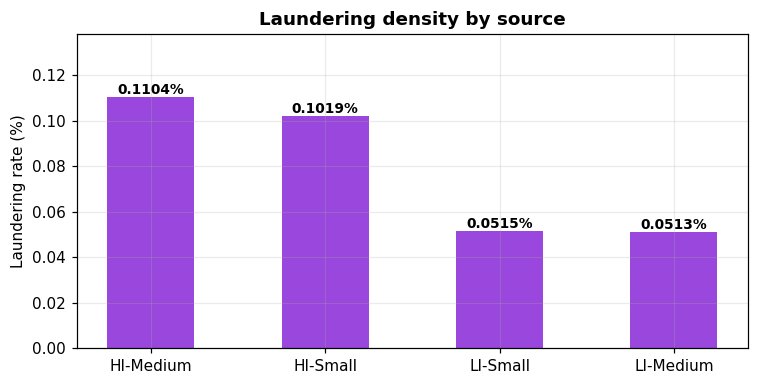


Highest density: HI-Medium at 0.1104%


In [4]:
source_table = eu.compare_sources(DATA_DIR)
display(source_table)

avail = source_table.dropna(subset=["Rate %"])
if len(avail) > 1:
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.bar(avail["Source"], avail["Rate %"], color=PURPLE, width=0.5)
    for x, v in zip(avail["Source"], avail["Rate %"]):
        ax.text(x, v, f"{v:.4f}%", ha="center", va="bottom", fontweight="bold", fontsize=9)
    ax.set_ylabel("Laundering rate (%)")
    ax.set_title("Laundering density by source", fontweight="bold")
    ax.set_ylim(0, avail["Rate %"].max() * 1.25)
    plt.tight_layout(); plt.show()

    top = avail.iloc[0]
    print(f"\nHighest density: {top['Source']} at {top['Rate %']}%")

**Decision: HI-Small.** It has the highest proportion of laundering of the four sources,
which gives us the most positive examples to learn from without changing the fact that
the problem is severely imbalanced.

Worth recording: an earlier version of this analysis stated in writing that HI-Medium
was chosen for having the highest proportion, while its code actually filtered for
HI-Small. The code was right and the text was wrong, in two separate ways. That is the
reason for the rule at the top of this notebook that every written number must appear in
the output above it.

<a id="4-account-linking"></a>
## <span style="color:#9947dc">4. Attaching account details</span>

**Why.** The transaction file only gives account numbers and bank codes. The bank names,
entity names and entity IDs live in a separate accounts file. We need them joined on
before we can ask anything about who is transacting, which countries are involved, or
whether both sides belong to the same owner.

**How.** Two left joins. The sender side matches on `(From Bank, Account)` and the
receiver side on `(To Bank, Account.1)`, both against `(Bank ID, Account Number)` in the
accounts file. We use `validate="many_to_one"` and assert the row count is unchanged, so
a bad key cannot silently duplicate or drop transactions. Left joins mean unmatched rows
survive as blanks and get counted rather than disappearing.

**What the output shows.** 5,078,345 rows before and after. Zero unmatched senders and
zero unmatched receivers — every account in the transaction file exists in the accounts
file. That is a clean result and it means entity and bank features are available on
every row with no gaps to handle.

In [5]:
trans, link_stats = eu.link_accounts(trans, accounts)
display(pd.Series(link_stats).rename("Value").to_frame())

if link_stats["Sender unmatched"] or link_stats["Receiver unmatched"]:
    print("\nUnmatched rows present — inspect before relying on entity features.")
else:
    print("\nEvery sender and receiver resolved to an account record.")

,Value
Rows,5078345
Sender unmatched,0
Receiver unmatched,0



Every sender and receiver resolved to an account record.


<a id="5-pattern-linking"></a>
## <span style="color:#9947dc">5. Checking the labels against the patterns file</span>

**Why.** This is the most important section in the notebook, and it addresses an open
item on our to-do list: verify the labels.

The transaction file marks 5,177 rows as laundering but gives no reason. The patterns
file lists transfers that are both marked as laundering **and** attributed to a named
scheme. Joining the two does two things for us:

1. **It checks the labels.** Any row flagged as laundering that the patterns file cannot
   explain is either a quirk of how the data was generated or a mistake in our join. We
   should not claim the labels are verified without knowing which.
2. **It recovers the case structure.** The `Attempt ID` turns scattered flagged rows into
   connected schemes. That matters because our project investigates *cases*, not isolated
   transactions, and these attempts are the only ground truth we have about what a case
   looks like.

**How.** We join on `(Timestamp, From Bank, Account, To Bank, Account.1, Amount Paid)`.

Two traps we had to handle. The account pair alone is not a unique key, because the same
two accounts transact repeatedly — so the timestamp and amount are both part of the key.
And bank codes are written zero-padded in the `.txt` file (`021174`) but unpadded in the
CSV (`21174`), so both sides are converted to integers before matching. Without that, the
join would have returned almost nothing while appearing to work.

**What the output shows.** The join is sound: all 3,209 pattern rows matched, and zero
rows matched onto transactions that are *not* flagged, which is the consistency check
that would have caught a bad key.

The real finding is the gap. Of 5,177 flagged transactions, only **3,209 (62%) are
explained** by a named laundering attempt. **1,968 (38%) are flagged with no scheme
behind them at all.** The next cell looks at what those are.

In [6]:
trans, reconciliation, coverage = eu.link_patterns(trans, patterns)

print("Label reconciliation")
display(reconciliation)

print("\nPattern file coverage")
display(pd.Series(coverage).rename("Rows").to_frame())

flagged = int(trans["Is Laundering"].sum())
explained = int((trans["Is Laundering"].eq(1) & trans["In Patterns File"]).sum())
print(f"\nFlagged rows          : {flagged:,}")
print(f"Explained by patterns : {explained:,} ({explained / flagged * 100:.1f}%)")
print(f"Unexplained           : {flagged - explained:,} "
      f"({(flagged - explained) / flagged * 100:.1f}%)")

if coverage["Pattern rows unmatched"]:
    print("\nWARNING: pattern rows failed to match. Inspect before trusting the join:")
    display(patterns.merge(trans[eu.PATTERN_JOIN_KEYS].assign(_m=1),
                           on=eu.PATTERN_JOIN_KEYS, how="left")
            .query("_m.isna()").head(10))

Label reconciliation


,Category,Rows,Note
0,Flagged and in patterns file,3209,Label corroborated by a named laundering attempt
1,"Flagged, not in patterns file",1968,Flagged with no corroborating attempt - invest...
2,"In patterns file, not flagged",0,Join error or label inconsistency - must be 0
3,Unflagged background,5073168,Legitimate traffic



Pattern file coverage


,Rows
Pattern rows in file,3209
Pattern rows matched,3209
Pattern rows unmatched,0
Duplicate join keys dropped,0



Flagged rows          : 5,177
Explained by patterns : 3,209 (62.0%)
Unexplained           : 1,968 (38.0%)


### What the unexplained 38% look like

**Why.** Before deciding what to do with 1,968 unexplained positives, we should know
whether they resemble the explained ones. If they look the same, they are probably
schemes the generator simply chose not to write to the patterns file. If they look
different, they are a separate population and we need to handle them deliberately.

**How.** Split the flagged rows into "explained" and "unexplained" and compare them on
payment format, amount and bank relationship.

**What the output shows.** They are clearly two different populations.

| | Explained (3,209) | Unexplained (1,968) |
|---|---|---|
| ACH | 99.97% | 64.79% |
| Cheque | 0% | 16.46% |
| Credit Card | 0% | 10.47% |
| Cash | 0% | 5.49% |
| Bitcoin | 0.03% | 2.79% |
| Median amount | 12,576.93 | 2,955.04 |

Doing the arithmetic against the payment-format counts in section 8 makes this sharper
than the table alone suggests: **every single non-ACH positive is unexplained.** That is
324 Cheque + 206 Credit Card + 108 Cash + 55 Bitcoin = 693 transactions, plus a further
1,275 ACH positives with no attempt record.

So the patterns file documents only structured ACH schemes. Everything else is flagged
with no topology attached, and the unexplained group also moves much smaller amounts
(median around 2,955 against 12,577).

**What this means for the project.** Our system reconstructs cases, and 38% of positives
have no case to reconstruct. We have to choose: either scope the investigation side to
the 370 documented attempts and treat the remaining 1,968 as classifier-only positives,
or exclude them. Either is defensible. Not deciding is not.

In [7]:
pos = trans[trans["Is Laundering"].eq(1)].copy()
pos["Group"] = np.where(pos["In Patterns File"], "Explained", "Unexplained")

if pos["Group"].nunique() > 1:
    comp = pos.groupby("Group").agg(
        Rows=("Amount Paid", "size"),
        Median_Amount=("Amount Paid", "median"),
        Mean_Amount=("Amount Paid", "mean"),
        Pct_ACH=("Payment Format", lambda s: (s == "ACH").mean() * 100),
        Pct_Cross_Bank=("From Bank", lambda s: pd.NA),
        Distinct_Senders=("Account", "nunique"),
    ).round(2)
    comp["Pct_Cross_Bank"] = pos.groupby("Group").apply(
        lambda g: (g["From Bank"] != g["To Bank"]).mean() * 100, include_groups=False
    ).round(2)
    display(comp)

    print("\nPayment format split")
    display(pd.crosstab(pos["Group"], pos["Payment Format"], normalize="index")
            .mul(100).round(2))
else:
    print("All flagged rows fall in one group — nothing to contrast.")

,Rows,Median_Amount,Mean_Amount,Pct_ACH,Pct_Cross_Bank,Distinct_Senders
Group,,,,,,
Explained,3209,12576.93,2720119.48,99.97,97.57,2071
Unexplained,1968,2955.04,90621767.57,64.79,98.73,1315



Payment format split


Payment Format,ACH,Bitcoin,Cash,Cheque,Credit Card
Group,,,,,
Explained,99.97,0.03,0.00,0.00,0.00
Unexplained,64.79,2.79,5.49,16.46,10.47


<a id="6-attempt-structure"></a>
## <span style="color:#9947dc">6. What a laundering scheme looks like structurally</span>

**Why.** Each attempt is one connected laundering scheme. How big it is, how long it
runs and how many accounts it touches tells us what our system has to reconstruct. The
time span also decides whether we can split the data by date without cutting schemes in
half.

**How.** Group the pattern transfers by `Attempt ID` and summarise size, duration,
accounts and banks per attempt, then break that down by topology.

**What the output shows.**

370 attempts across 8 topologies. By volume of transfers: GATHER-SCATTER (51 attempts,
716 transfers), SCATTER-GATHER (44, 626), STACK (43, 466), FAN-OUT (48, 342), FAN-IN
(40, 318), CYCLE (54, 287), BIPARTITE (49, 263), RANDOM (41, 191).

Note that CYCLE has the most attempts (54) but relatively few transfers, because cycles
are short — a median of 4 transfers. GATHER-SCATTER and SCATTER-GATHER are the big ones
at a median of 14 transfers each.

Schemes are small. Median 6.5 transfers, mean 8.67, maximum 32. **43 of the 370 attempts
consist of a single transfer**, which is worth remembering: for those, there is no
network to investigate at all.

Schemes are also short-lived. Median duration 3.11 days, mean 2.81, maximum 8.43 days.
This is good news for a date-based split — a cutoff only cuts through schemes running
across it, and most schemes are over within a few days.

,Attempts,Rows,Median_Rows,Max_Rows,Median_Span_Days,Median_Accounts,Rows %
Pattern Type,,,,,,,
GATHER-SCATTER,51,716,14.0,28,6.28,15.0,22.3
SCATTER-GATHER,44,626,14.0,32,3.70,9.0,19.5
STACK,43,466,10.0,30,3.05,15.0,14.5
FAN-OUT,48,342,7.0,16,3.19,8.0,10.7
FAN-IN,40,318,8.0,16,3.54,9.0,9.9
CYCLE,54,287,4.0,12,3.00,4.0,8.9
BIPARTITE,49,263,4.0,15,1.01,8.0,8.2
RANDOM,41,191,3.0,11,1.92,4.0,6.0


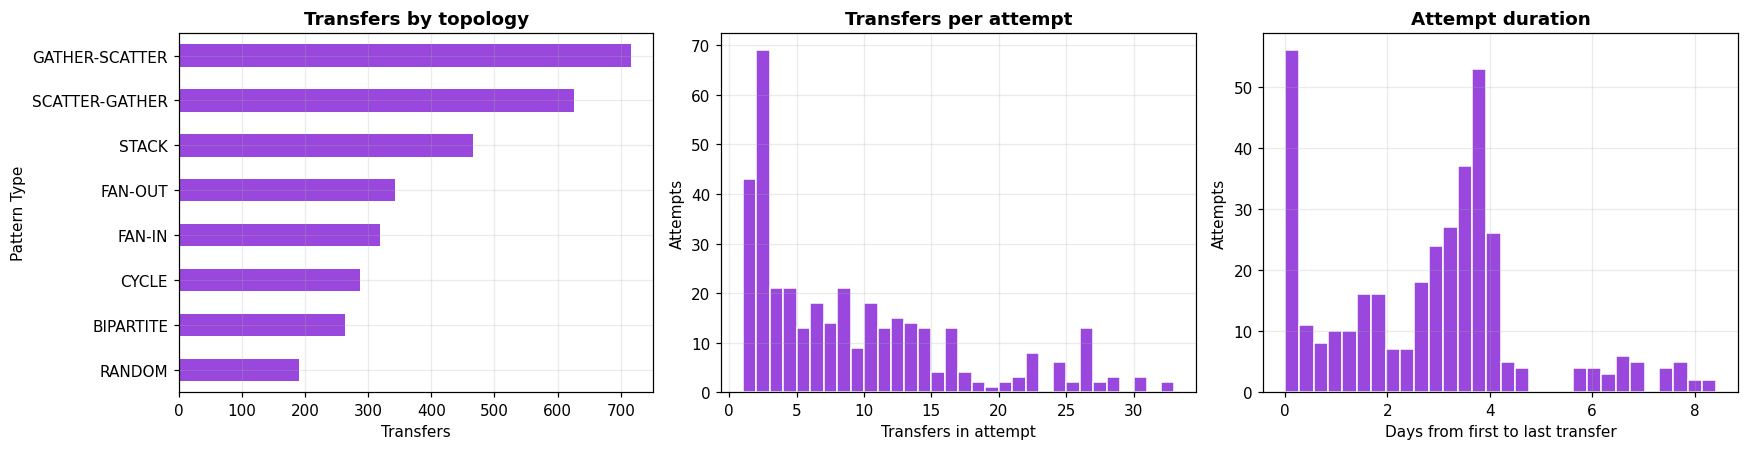

Transfers per attempt:
count    370.00
mean       8.67
std        7.66
min        1.00
25%        2.00
50%        6.50
75%       13.00
max       32.00

Single-transfer attempts: 43 of 370

Span in days:
count    370.00
mean       2.81
std        1.93
min        0.00
25%        1.37
50%        3.11
75%        3.79
max        8.43


In [8]:
profile = eu.attempt_profile(patterns)

by_type = profile.groupby("Pattern Type").agg(
    Attempts=("Rows", "size"),
    Rows=("Rows", "sum"),
    Median_Rows=("Rows", "median"),
    Max_Rows=("Rows", "max"),
    Median_Span_Days=("Span (days)", "median"),
    Median_Accounts=("Distinct Accounts", "median"),
).sort_values("Rows", ascending=False).round(2)
by_type["Rows %"] = (by_type["Rows"] / by_type["Rows"].sum() * 100).round(1)
display(by_type)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
by_type["Rows"].sort_values().plot(kind="barh", ax=ax[0], color=PURPLE)
ax[0].set_title("Transfers by topology", fontweight="bold"); ax[0].set_xlabel("Transfers")

ax[1].hist(profile["Rows"], bins=range(1, int(profile["Rows"].max()) + 2),
           color=PURPLE, edgecolor="white")
ax[1].set_title("Transfers per attempt", fontweight="bold")
ax[1].set_xlabel("Transfers in attempt"); ax[1].set_ylabel("Attempts")

ax[2].hist(profile["Span (days)"], bins=30, color=PURPLE, edgecolor="white")
ax[2].set_title("Attempt duration", fontweight="bold")
ax[2].set_xlabel("Days from first to last transfer"); ax[2].set_ylabel("Attempts")
plt.tight_layout(); plt.show()

print("Transfers per attempt:")
print(profile["Rows"].describe().round(2).to_string())
print(f"\nSingle-transfer attempts: {(profile['Rows'] == 1).sum()} of {len(profile)}")
print("\nSpan in days:")
print(profile["Span (days)"].describe().round(2).to_string())

In [9]:
# Header metadata the original parser discarded — the generator's own description.
meta = (attempts.dropna(subset=["Header Meta"])
        .groupby(["Pattern Type", "Header Meta"]).size()
        .rename("Attempts").reset_index()
        .sort_values(["Pattern Type", "Attempts"], ascending=[True, False]))
display(meta.head(30))

no_meta = attempts[attempts["Header Meta"].isna()]["Pattern Type"].value_counts()
if len(no_meta):
    print("\nTopologies whose headers carry no parameters:")
    print(no_meta.to_string())

,Pattern Type,Header Meta,Attempts
3,CYCLE,Max 2 hops,14
4,CYCLE,Max 3 hops,9
5,CYCLE,Max 4 hops,7
0,CYCLE,Max 10 hops,6
8,CYCLE,Max 7 hops,5
1,CYCLE,Max 11 hops,4
9,CYCLE,Max 8 hops,4
6,CYCLE,Max 5 hops,3
2,CYCLE,Max 12 hops,1
7,CYCLE,Max 6 hops,1



Topologies whose headers carry no parameters:
Pattern Type
BIPARTITE         49
SCATTER-GATHER    44
STACK             43


In [10]:
# Accounts shared between attempts — decides whether attempts can be split independently.
acc_attempts = eu.pattern_accounts(patterns)
shared = acc_attempts[acc_attempts["Attempts"] > 1]

print(f"Distinct accounts in laundering attempts : {len(acc_attempts):,}")
print(f"Accounts appearing in >1 attempt         : {len(shared):,} "
      f"({len(shared) / len(acc_attempts) * 100:.1f}%)")
print(f"Most attempts touched by one account     : {acc_attempts['Attempts'].max()}")
display(acc_attempts.head(10))

Distinct accounts in laundering attempts : 3,170
Accounts appearing in >1 attempt         : 100 (3.2%)
Most attempts touched by one account     : 32


,Account ID,Attempts
900,8021353D0,32
956,80266F880,32
3153,812A09CF0,22
3097,811C597B0,22
3154,812A09D40,22
3098,811C599A0,21
3083,811B83280,20
3168,812D22980,19
3160,812D0C3C0,19
3161,812D0C600,17


### Accounts are shared between schemes

**What the output shows.** 3,170 distinct accounts take part in laundering attempts.
100 of them (3.2%) appear in more than one attempt, and one account appears in 32
different schemes.

**Why this matters.** The attempts are not independent of each other. If we split rows
randomly into training and validation sets, the same scheme — and sometimes the same
account across several schemes — lands on both sides. Validation would then be measuring
whether the model memorised accounts it has already seen, not whether it can detect
laundering. Section 21 measures how bad this gets for each candidate cutoff.

<a id="7-target"></a>
## <span style="color:#9947dc">7. How rare laundering is</span>

**Why.** The class balance determines almost every modelling decision that follows:
which metrics mean anything, whether accuracy is usable at all, and whether we need to
reweight or resample.

**How.** Count the two classes over the whole file.

,Class,Count,Percentage
0,Legitimate (0),5073168,99.8981
1,Laundering (1),5177,0.1019


Laundering rate      : 0.1019%
Imbalance ratio      : 1 : 979
Positives            : 5,177


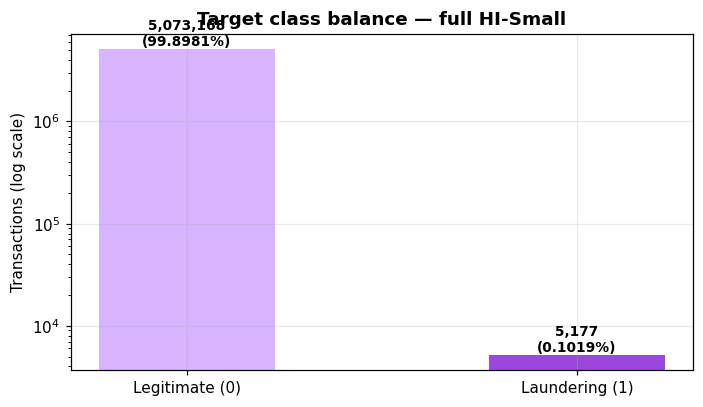

In [11]:
counts = trans["Is Laundering"].value_counts().sort_index()
balance = pd.DataFrame({
    "Class": ["Legitimate (0)", "Laundering (1)"],
    "Count": counts.values,
    "Percentage": (counts / len(trans) * 100).round(4).values,
})
display(balance)

rate = trans["Is Laundering"].mean()
print(f"Laundering rate      : {rate * 100:.4f}%")
print(f"Imbalance ratio      : 1 : {int((1 - rate) / rate):,}")
print(f"Positives            : {int(counts.get(1, 0)):,}")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
bars = ax.bar(balance["Class"], balance["Count"], color=[LILAC, PURPLE], width=0.45)
for b, c, p in zip(bars, balance["Count"], balance["Percentage"]):
    ax.text(b.get_x() + b.get_width() / 2, c, f"{c:,}\n({p:.4f}%)",
            ha="center", va="bottom", fontweight="bold", fontsize=9)
ax.set_yscale("log"); ax.set_ylabel("Transactions (log scale)")
ax.set_title("Target class balance — full HI-Small", fontweight="bold")
plt.tight_layout(); plt.show()

**What the output shows.** 5,177 laundering transactions out of 5,078,345 — **0.1019%**,
or roughly **1 in 979**.

This is the real rate for the complete file. Two consequences:

- **Accuracy is meaningless here.** A model that predicts "not laundering" every single
  time scores 99.9% accuracy and catches nothing. We evaluate with precision, recall and
  precision-recall AUC instead.
- **If preprocessing enriches the positives** by throwing away negatives, the enrichment
  factor has to be stated, and final numbers have to be reported on data at this natural
  rate. Precision depends on how common the positive class is — a model showing 60%
  precision on an enriched sample will show far less on realistic data. That is a
  reporting error that is easy to make and hard to defend.

<a id="8-payment-format"></a>
## <span style="color:#9947dc">8. Payment format</span>

**Why.** Payment format is the single most obvious candidate signal, so it is worth
measuring carefully — including whether it is measuring laundering or measuring how the
dataset was built.

**How.** Volume, laundering count and laundering rate for each of the 7 formats.

,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Payment Format,,,,,
ACH,600797,4483,0.7462,86.59,11.83
Bitcoin,146091,56,0.0383,1.08,2.88
Cash,490891,108,0.0220,2.09,9.67
Cheque,1864331,324,0.0174,6.26,36.71
Credit Card,1323324,206,0.0156,3.98,26.06
Reinvestment,481056,0,0.0000,0.00,9.47
Wire,171855,0,0.0000,0.00,3.38


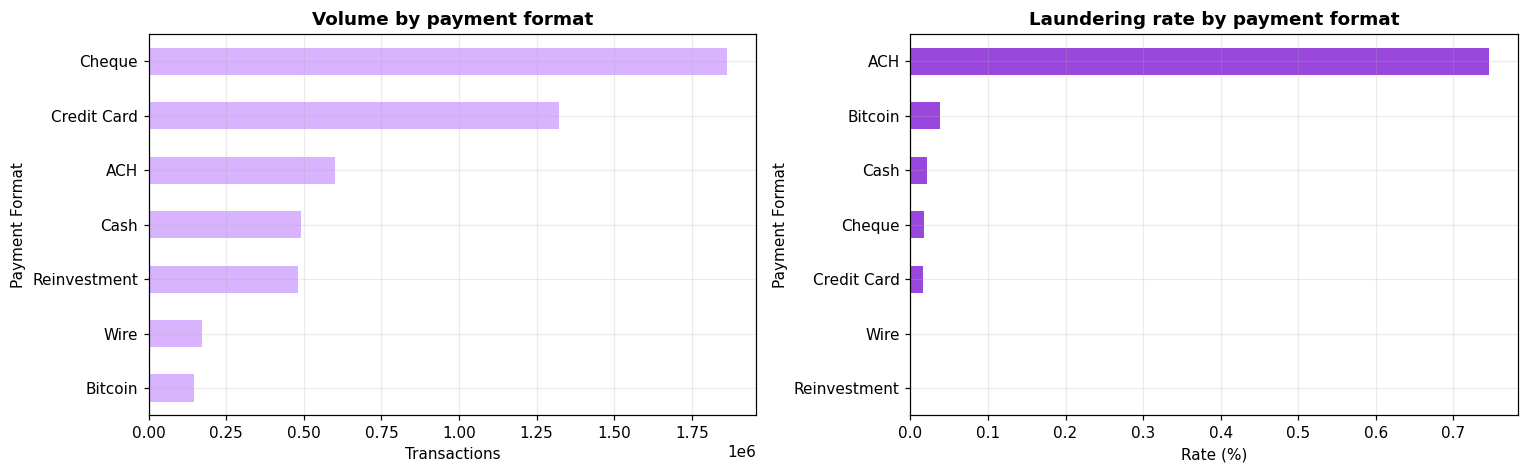

Formats with zero laundering:
                Transactions  Share of Volume %
Payment Format                                 
Reinvestment          481056               9.47
Wire                  171855               3.38


In [12]:
fmt = eu.risk_by(trans, "Payment Format")
display(fmt)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
fmt["Transactions"].sort_values().plot(kind="barh", ax=ax[0], color=LILAC)
ax[0].set_title("Volume by payment format", fontweight="bold"); ax[0].set_xlabel("Transactions")
fmt["Rate %"].sort_values().plot(kind="barh", ax=ax[1], color=PURPLE)
ax[1].set_title("Laundering rate by payment format", fontweight="bold"); ax[1].set_xlabel("Rate (%)")
plt.tight_layout(); plt.show()

clean = fmt[fmt["Laundering"] == 0]
if len(clean):
    print("Formats with zero laundering:")
    print(clean[["Transactions", "Share of Volume %"]].to_string())

**What the output shows.**

| Format | Transactions | Laundering | Rate | Share of all laundering |
|---|---|---|---|---|
| ACH | 600,797 | 4,483 | 0.746% | 86.6% |
| Bitcoin | 146,091 | 56 | 0.038% | 1.1% |
| Cash | 490,891 | 108 | 0.022% | 2.1% |
| Cheque | 1,864,331 | 324 | 0.017% | 6.3% |
| Credit Card | 1,323,324 | 206 | 0.016% | 4.0% |
| Reinvestment | 481,056 | 0 | 0% | 0% |
| Wire | 171,855 | 0 | 0% | 0% |

ACH is 11.8% of transactions but 86.6% of all laundering, with a rate roughly 20 times
higher than the next format.

**This needs a strong caution in the report.** Wire and Reinvestment have *exactly* zero
laundering across 652,911 transactions between them. Real money laundering does not
avoid wire transfers — wires are one of the most common laundering channels in practice.
What this actually shows is that the generator only injected laundering into certain
formats. Our model will learn the rule and score very well on it, and that performance
will not transfer to real data.

So: report payment format as a property of the dataset, not as a finding about money
laundering. The honest framing is "in this dataset, laundering was injected almost
entirely through ACH", not "ACH is the risky channel".

The cell below makes the same point from the other direction: the patterns file is
3,208 ACH transfers and exactly 1 Bitcoin transfer. Section 19 also shows that
Reinvestment's clean record has a second, more mundane explanation.

In [13]:
print("Payment format within the patterns file:")
print(patterns["Payment Format"].value_counts().to_string())
print("\nPayment format among flagged transactions:")
print(trans[trans["Is Laundering"].eq(1)]["Payment Format"]
      .value_counts().to_string())

Payment format within the patterns file:
Payment Format
ACH        3208
Bitcoin       1

Payment format among flagged transactions:
Payment Format
ACH             4483
Cheque           324
Credit Card      206
Cash             108
Bitcoin           56
Reinvestment       0
Wire               0


<a id="9-bank-relationship"></a>
## <span style="color:#9947dc">9. Transfers within a bank vs between banks</span>

**Why.** Moving money between institutions breaks the audit trail, because no single
bank sees the whole chain. If the data reflects that, same-bank and cross-bank transfers
should carry different risk.

**How.** Compare transactions where `From Bank` equals `To Bank` against those where it
does not.

**What the output shows.** Cross-bank transfers are 86.4% of volume but carry **98.0% of
all laundering** — 5,074 of 5,177 cases. The rate is 0.1157% for cross-bank against
0.0149% for same-bank, nearly 8 times higher.

This is a real and expected pattern, and unlike the payment-format result it matches how
laundering genuinely works. It gives us a simple, cheap feature.

,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Relationship,,,,,
Inter-Bank,4387013,5074,0.1157,98.01,86.39
Intra-Bank,691332,103,0.0149,1.99,13.61


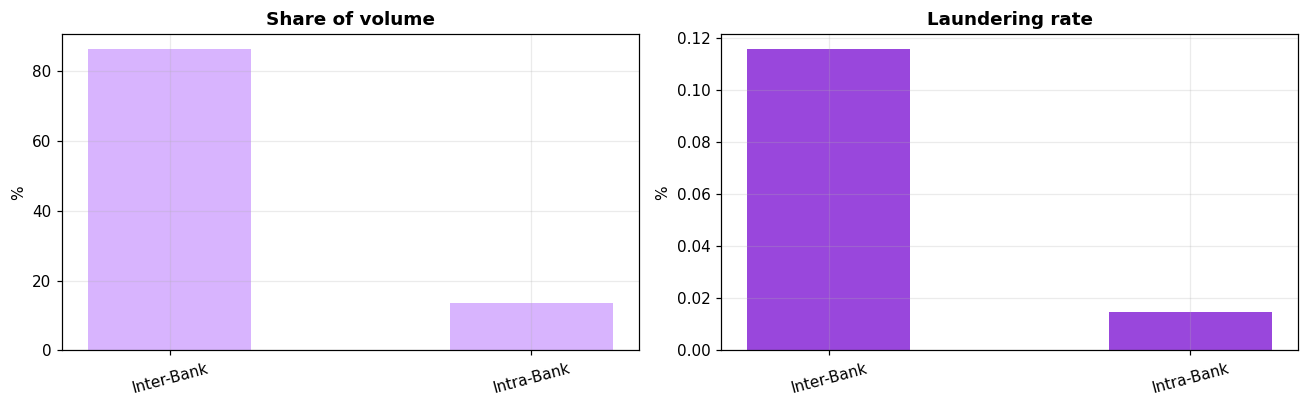

In [14]:
rel = eu.bank_relationship(trans)
display(rel)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(rel.index, rel["Share of Volume %"], color=LILAC, width=0.45)
ax[0].set_title("Share of volume", fontweight="bold"); ax[0].set_ylabel("%")
ax[1].bar(rel.index, rel["Rate %"], color=PURPLE, width=0.45)
ax[1].set_title("Laundering rate", fontweight="bold"); ax[1].set_ylabel("%")
for a in ax: a.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

<a id="10-amounts"></a>
## <span style="color:#9947dc">10. Amounts and currencies</span>

**Why.** Two questions. Do laundering transactions move different amounts than normal
ones? And do we need both `Amount Paid` and `Amount Received`, or is one redundant?

The second question matters because carrying two nearly identical columns into a model
creates multicollinearity, which makes linear-model coefficients unstable and harder to
interpret.

**How.** Amounts span from fractions of a cent to over a trillion, so we show them on a
`log10` scale to make the distributions readable. Then we check directly whether the two
amount columns ever disagree, and split that by whether the currencies match.

**What the output shows.**

**Amounts differ clearly by class.** Median legitimate transaction: 1,410.99. Median
laundering transaction: 8,667.21 — about 6 times larger. Laundering also avoids the very
small amounts: its 25th percentile is 2,634.97 against 184.16 for legitimate traffic.
This is a genuine, usable signal.

**The two amount columns are redundant except in one specific case.** Of 5,006,175
same-currency transactions, the paid and received amounts are identical in *every single
one*. Of 72,158 cross-currency transactions, they always differ — which is just the
exchange rate. Overall correlation of the logged amounts is 0.9976.

Also worth noting: **all 5,177 laundering transactions are same-currency.** Not one
involves a currency conversion.

**Decision for preprocessing:** keep one amount column, add a currency-mismatch flag,
and add the paid/received ratio as an exchange-rate feature for the 1.42% of rows where
it is meaningful. Dropping the second amount column loses nothing.

**Currency risk:** Saudi Riyal stands out at 0.4202%, roughly four times the rate of
every other currency (Euro 0.1174%, US Dollar 0.1009%, and everything else between
0.038% and 0.10%). 374 of the 5,177 positives are in Saudi Riyal. Section 15 shows the
same thing from the jurisdiction angle.

Is Laundering                     0             1
Amount Paid     count  5.073168e+06  5.177000e+03
                mean   4.477000e+06  3.613531e+07
                std    8.688463e+08  1.527919e+09
                min    0.000000e+00  0.000000e+00
                25%    1.841600e+02  2.634970e+03
                50%    1.410990e+03  8.667210e+03
                75%    1.227934e+04  1.883227e+04
                max    1.046302e+12  8.485314e+10
Amount Received count  5.073168e+06  5.177000e+03
                mean   5.957962e+06  3.613531e+07
                std    1.036563e+09  1.527919e+09
                min    0.000000e+00  0.000000e+00
                25%    1.830700e+02  2.634970e+03
                50%    1.407510e+03  8.667210e+03
                75%    1.232251e+04  1.883227e+04
                max    1.046302e+12  8.485314e+10

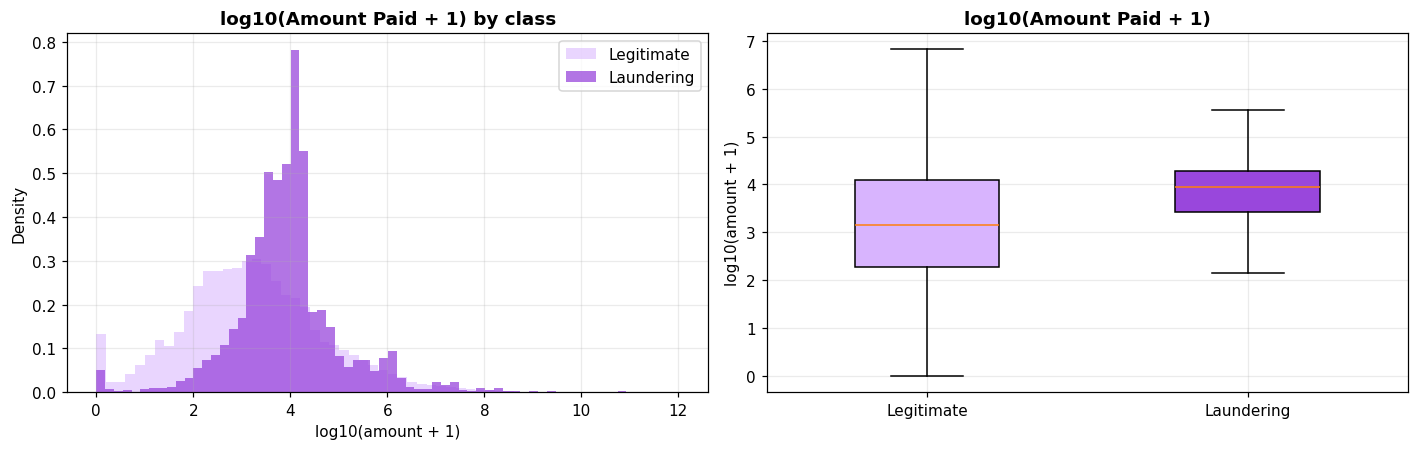

Median amount, legitimate : 1,410.99
Median amount, laundering : 8,667.21


In [15]:
desc = trans.groupby("Is Laundering")[["Amount Paid", "Amount Received"]].describe().T
display(desc.round(2))

log_paid = np.log10(trans["Amount Paid"].clip(lower=0) + 1)
legit = log_paid[trans["Is Laundering"].eq(0)]
laund = log_paid[trans["Is Laundering"].eq(1)]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].hist(legit, bins=60, density=True, alpha=0.55, color=LILAC, label="Legitimate")
ax[0].hist(laund, bins=60, density=True, alpha=0.75, color=PURPLE, label="Laundering")
ax[0].set_title("log10(Amount Paid + 1) by class", fontweight="bold")
ax[0].set_xlabel("log10(amount + 1)"); ax[0].set_ylabel("Density"); ax[0].legend()

bp = ax[1].boxplot([legit.values, laund.values], patch_artist=True, widths=0.45,
                   tick_labels=["Legitimate", "Laundering"], showfliers=False)
for patch, col in zip(bp["boxes"], [LILAC, PURPLE]):
    patch.set_facecolor(col)
ax[1].set_title("log10(Amount Paid + 1)", fontweight="bold")
ax[1].set_ylabel("log10(amount + 1)")
plt.tight_layout(); plt.show()

print(f"Median amount, legitimate : {trans.loc[trans['Is Laundering'].eq(0), 'Amount Paid'].median():,.2f}")
print(f"Median amount, laundering : {trans.loc[trans['Is Laundering'].eq(1), 'Amount Paid'].median():,.2f}")

In [16]:
print("Do Amount Paid and Amount Received ever differ?")
display(eu.currency_consistency(trans))

mismatch = trans["Payment Currency"].ne(trans["Receiving Currency"])
differ = trans["Amount Paid"].ne(trans["Amount Received"])
print(f"\nCross-currency rows        : {mismatch.sum():,} ({mismatch.mean() * 100:.2f}%)")
print(f"Rows where amounts differ  : {differ.sum():,} ({differ.mean() * 100:.2f}%)")
print(f"Correlation of the two log amounts: "
      f"{np.corrcoef(np.log1p(trans['Amount Paid'].clip(lower=0)), np.log1p(trans['Amount Received'].clip(lower=0)))[0, 1]:.6f}")
print("\nIf amounts differ only on cross-currency rows, the pair reduces to one amount")
print("plus an FX ratio and a mismatch flag. Decide in preprocessing, from these numbers.")

Do Amount Paid and Amount Received ever differ?


col_0,Amounts differ,Amounts identical,Laundering
row_0,,,
Cross currency,72158,12,0
Same currency,0,5006175,5177



Cross-currency rows        : 72,170 (1.42%)
Rows where amounts differ  : 72,158 (1.42%)
Correlation of the two log amounts: 0.997620

If amounts differ only on cross-currency rows, the pair reduces to one amount
plus an FX ratio and a mismatch flag. Decide in preprocessing, from these numbers.


In [17]:
cur = eu.risk_by(trans, "Payment Currency")
display(cur)

,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Payment Currency,,,,,
Saudi Riyal,89014,374,0.4202,7.22,1.75
Euro,1168297,1372,0.1174,26.50,23.01
US Dollar,1895172,1912,0.1009,36.93,37.32
Yen,155209,155,0.0999,2.99,3.06
Australian Dollar,136769,127,0.0929,2.45,2.69
Canadian Dollar,140042,128,0.0914,2.47,2.76
Rupee,190202,167,0.0878,3.23,3.75
Yuan,213752,184,0.0861,3.55,4.21
Ruble,155178,133,0.0857,2.57,3.06


<a id="11-temporal"></a>
## <span style="color:#9947dc">11. Behaviour over time</span>

**Why.** We need to know whether laundering has a timing signature, and — more
practically — whether the data is evenly distributed over the 17 days, because that
decides whether we can hold out a later period as a test set.

**How.** Daily volume and laundering rate, then hour of day and day of week, then the
gap between consecutive transactions for the same account. All of this depends on the
sort we did in section 1.

**What the output shows — and this is the most consequential finding in the notebook.**

**The data effectively stops on 10 September.**

| Date | Transactions | Laundering | Rate |
|---|---|---|---|
| 09 Sep | 654,467 | 514 | 0.079% |
| 10 Sep | 208,325 | 442 | 0.212% |
| **11 Sep** | **396** | **232** | **58.6%** |
| 12 Sep | 281 | 170 | 60.5% |
| 15 Sep | 46 | 28 | 60.9% |
| 18 Sep | 11 | 8 | 72.7% |

From 11 September onward the file contains 1,575 transactions, 655 of which are
laundering. The generator stopped producing normal background traffic but kept writing
out the remaining transfers of schemes that were still in progress. That tail is not a
time period we can analyse — it is leftover residue, and a model tested on it would be
tested on data that is 60% laundering.

**This rules out holding out the last few days.** Section 21 shows the consequence: a
15 September cutoff leaves 126 rows.

Daily volume is uneven before that too — 1,114,921 transactions on 1 September, 207,382
on 3 September, around 482,000 on the 5th through 8th. Worth one sentence in the report;
not a behavioural finding.

**Hour 0 is a dumping bucket.** 634,726 transactions at midnight against roughly 193,000
in every other hour — 3.3 times as many. Those are timestamps with no real time
attached, rounded to midnight. Its laundering rate (0.0277%) is the lowest of any hour,
which is an artefact of that padding, not a fact about midnight.

Excluding hour 0, laundering rate does vary mildly across the day, peaking at midday
(0.1741% at 12:00) and dipping overnight (0.0667% at 22:00). Weak, but real.

**The weekday table is misleading and should not be used.** Thursday shows 1,597,740
transactions and Sunday 207,837, but that is calendar arithmetic: 1 September 2022 was a
Thursday, so a 17-day window contains three Thursdays and Fridays but only two Sundays,
and the heavy early days land on them. Sunday's apparently high rate (0.3113%) is the
same artefact in reverse.

**Velocity is a real signal.** The gap between an account's consecutive transactions:
legitimate traffic has a median of 8 minutes and a 75th percentile of 103 minutes;
laundering has a median of **0 minutes** and a 75th percentile of 2 minutes. Laundering
moves in tight bursts. Section 17 pursues this further and finds something stronger.

,Transactions,Laundering,Rate %
Timestamp,,,
2022-09-01,1114921,322,0.0289
2022-09-02,754449,408,0.0541
2022-09-03,207382,391,0.1885
2022-09-04,207430,407,0.1962
2022-09-05,482650,471,0.0976
2022-09-06,482089,531,0.1101
2022-09-07,482751,497,0.1030
2022-09-08,482773,539,0.1116
2022-09-09,654467,514,0.0785


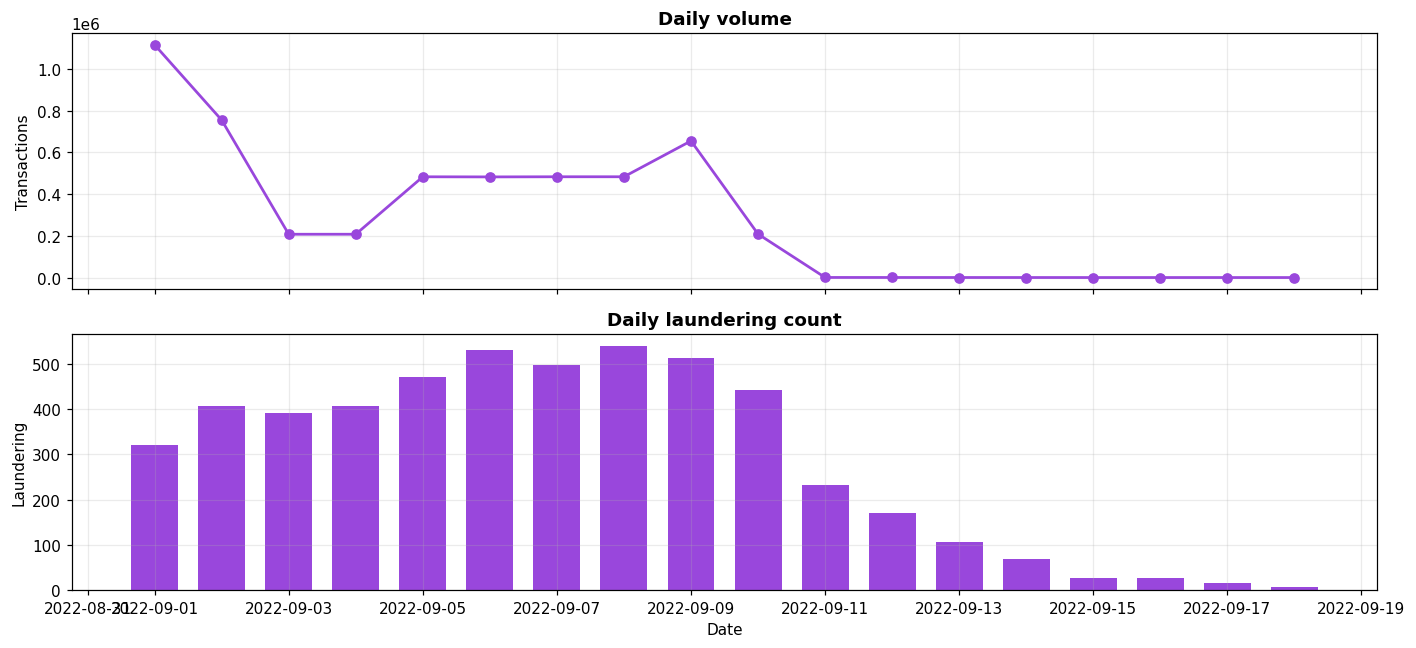

In [18]:
daily = trans.set_index("Timestamp").resample("D").agg(
    Transactions=("Is Laundering", "size"), Laundering=("Is Laundering", "sum"))
daily["Rate %"] = (daily["Laundering"] / daily["Transactions"] * 100).round(4)
display(daily)

fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].plot(daily.index, daily["Transactions"], color=PURPLE, marker="o", lw=1.8)
ax[0].set_ylabel("Transactions"); ax[0].set_title("Daily volume", fontweight="bold")
ax[1].bar(daily.index, daily["Laundering"], color=PURPLE, width=0.7)
ax[1].set_ylabel("Laundering"); ax[1].set_title("Daily laundering count", fontweight="bold")
ax[1].set_xlabel("Date")
plt.tight_layout(); plt.show()

,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Hour,,,,,
0,634726,176,0.0277,3.40,12.50
1,193728,152,0.0785,2.94,3.81
2,193143,165,0.0854,3.19,3.80
3,193249,146,0.0756,2.82,3.81
4,193166,154,0.0797,2.97,3.80
5,193900,188,0.0970,3.63,3.82
6,194456,207,0.1065,4.00,3.83
7,193336,195,0.1009,3.77,3.81
8,192921,258,0.1337,4.98,3.80


,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Weekday,,,,,
Monday,482931,641,0.1327,12.38,9.51
Tuesday,482273,637,0.1321,12.30,9.50
Wednesday,482872,567,0.1174,10.95,9.51
Thursday,1597740,889,0.0556,17.17,31.46
Friday,1408962,948,0.0673,18.31,27.74
Saturday,415730,848,0.2040,16.38,8.19
Sunday,207837,647,0.3113,12.50,4.09


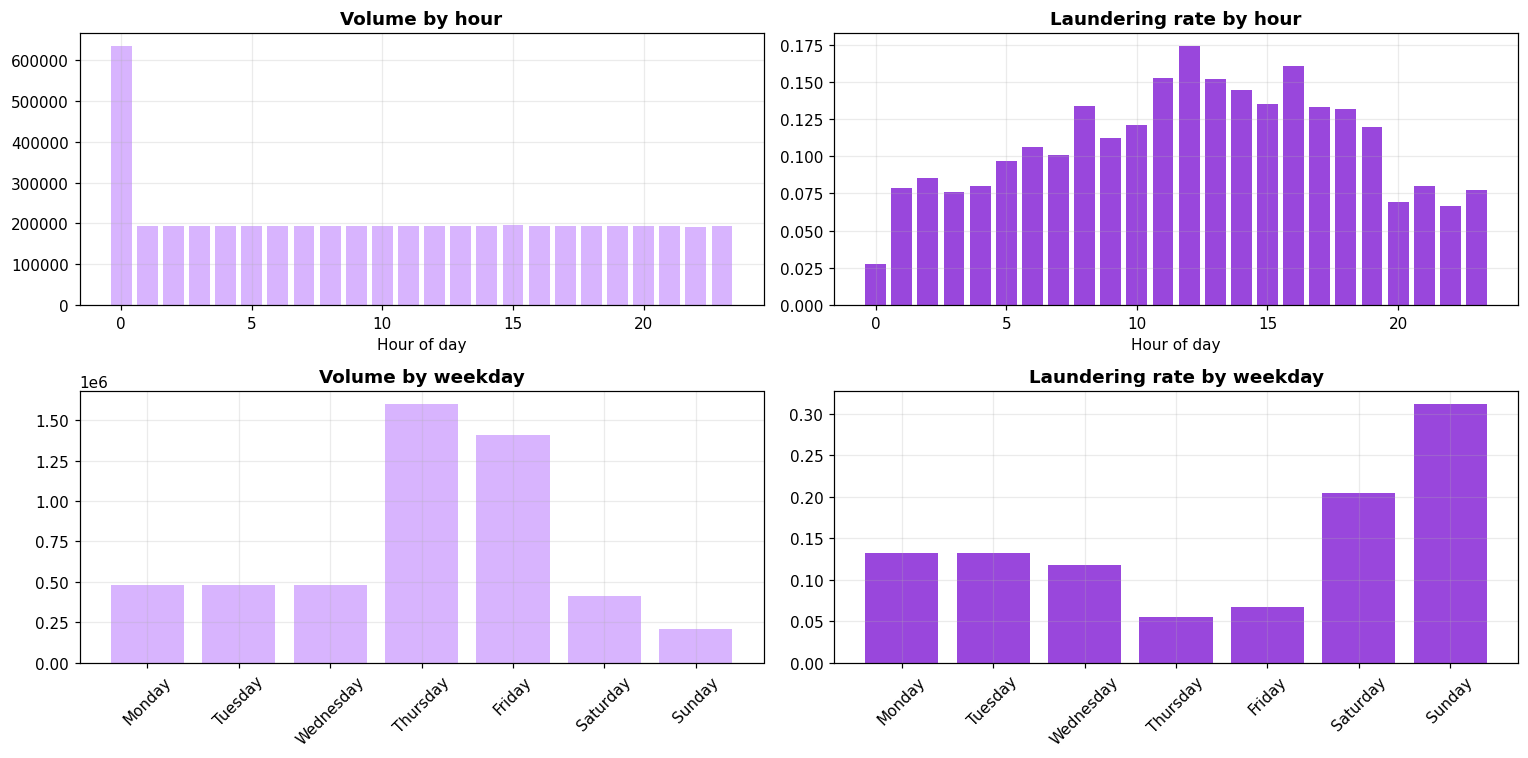

In [19]:
tt = trans.assign(Hour=trans["Timestamp"].dt.hour,
                  Weekday=trans["Timestamp"].dt.day_name())

hourly = eu.risk_by(tt, "Hour").sort_index()
display(hourly)

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekly = eu.risk_by(tt, "Weekday").reindex([d for d in order if d in tt["Weekday"].unique()])
display(weekly)

fig, ax = plt.subplots(2, 2, figsize=(14, 7))
ax[0, 0].bar(hourly.index, hourly["Transactions"], color=LILAC); ax[0, 0].set_title("Volume by hour", fontweight="bold")
ax[0, 1].bar(hourly.index, hourly["Rate %"], color=PURPLE); ax[0, 1].set_title("Laundering rate by hour", fontweight="bold")
ax[1, 0].bar(weekly.index, weekly["Transactions"], color=LILAC); ax[1, 0].set_title("Volume by weekday", fontweight="bold")
ax[1, 1].bar(weekly.index, weekly["Rate %"], color=PURPLE); ax[1, 1].set_title("Laundering rate by weekday", fontweight="bold")
for a in ax[1]: a.tick_params(axis="x", rotation=45)
for a in ax[0]: a.set_xlabel("Hour of day")
plt.tight_layout(); plt.show()

,count,mean,std,min,25%,50%,75%,max
Is Laundering,,,,,,,,
0,2042172.0,133.38,301.88,0.0,1.0,8.0,103.0,5710.0
1,1160.0,138.57,478.93,0.0,0.0,0.0,2.0,4896.0


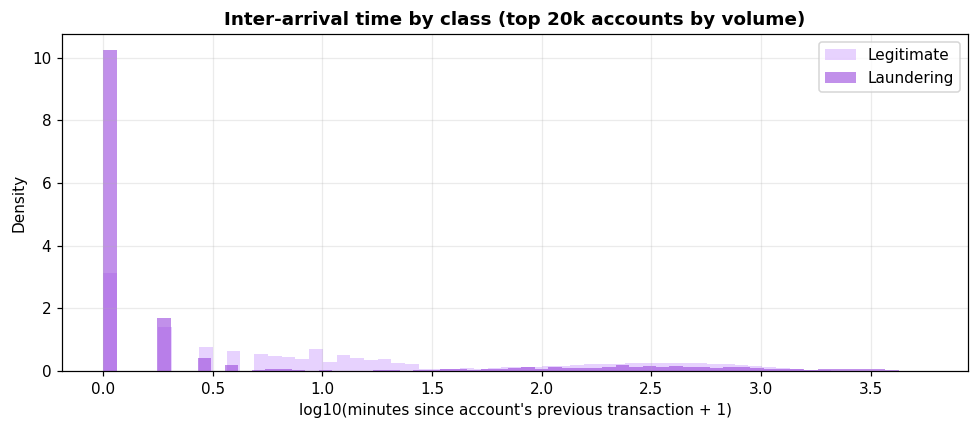

In [20]:
# Velocity: gap between consecutive transactions of the same sending account.
gaps = eu.interarrival(trans, by="Account", limit=20000)
by_class = gaps.groupby("Is Laundering")["Gap (min)"].describe().round(2)
display(by_class)

fig, ax = plt.subplots(figsize=(9, 4))
for label, colour, name in [(0, LILAC, "Legitimate"), (1, PURPLE, "Laundering")]:
    vals = gaps.loc[gaps["Is Laundering"].eq(label), "Gap (min)"]
    if len(vals):
        ax.hist(np.log10(vals + 1), bins=60, density=True, alpha=0.6,
                color=colour, label=name)
ax.set_xlabel("log10(minutes since account's previous transaction + 1)")
ax.set_ylabel("Density"); ax.legend()
ax.set_title("Inter-arrival time by class (top 20k accounts by volume)", fontweight="bold")
plt.tight_layout(); plt.show()

<a id="12-network"></a>
## <span style="color:#9947dc">12. Account network structure</span>

**Why.** Our system investigates accounts and the connections between them, not isolated
rows. So account-level structure — how many transactions an account makes, how many
different counterparties it deals with, whether money flows in or out — is the feature
family that matters most for this project. An earlier version of this analysis computed
none of it.

**How.** Aggregate every transaction to the account level across both the sending and
receiving roles, then compare accounts that touch at least one laundering transaction
against those that never do.

**What the output shows.** 515,080 distinct accounts, of which 6,357 (1.234%) are
involved in at least one laundering transaction.

The contrast is strong:

| | Clean accounts | Laundering-involved |
|---|---|---|
| Transactions (median) | 6 | 22 |
| Distinct counterparties (median) | 3 | 6 |
| Sent (median) | 2 | 4 |
| **Received (median)** | **2** | **13** |

The received count is the standout: laundering-involved accounts receive from about six
times as many sources as normal accounts, while sending only about twice as much. That
shape — many inbound, fewer outbound — is exactly what collection and consolidation
looks like.

One caution, which section 14 tests: a few accounts in this dataset are enormously more
active than everyone else, and they also touch laundering. We need to confirm they are
not the reason this table looks good.

In [21]:
acc = eu.account_activity(trans)
print(f"Distinct accounts: {len(acc):,}")
print(f"Accounts touching at least one laundering transaction: "
      f"{int(acc['Is Laundering Account'].sum()):,} "
      f"({acc['Is Laundering Account'].mean() * 100:.3f}%)")
display(acc.head())

print("\nLaundering-involved accounts vs the rest")
display(eu.activity_contrast(acc))

Distinct accounts: 515,080
Accounts touching at least one laundering transaction: 6,357 (1.234%)


,Account ID,Sent_Count,Sent_Total,Sent_Median,Out_Counterparties,Sent_Laundering,Recv_Count,Recv_Total,Recv_Median,In_Counterparties,Recv_Laundering,Degree,Counterparties,Laundering Rows,Is Laundering Account,Net Flow,Flow Ratio
0,100428660,168672.0,5.276229e+10,1061.850,14230.0,243.0,1084.0,479594.79,238.435,545.0,0.0,169756.0,14775.0,243.0,True,-5.276181e+10,110014.312728
1,1004286A8,103018.0,2.606938e+10,856.115,8846.0,158.0,653.0,251001.27,226.190,328.0,0.0,103671.0,9174.0,158.0,True,-2.606912e+10,103861.528180
2,1004286F0,18663.0,2.465736e+10,6280.890,1575.0,21.0,108.0,253933.88,1297.745,55.0,0.0,18771.0,1630.0,21.0,True,-2.465710e+10,97101.487139
3,100428738,13756.0,2.592168e+11,110011.380,1136.0,23.0,98.0,6304388.45,31938.580,51.0,0.0,13854.0,1187.0,23.0,True,-2.592105e+11,41116.879737
4,100428780,17264.0,3.739337e+11,72661.340,1421.0,21.0,117.0,10570889.95,20568.590,61.0,0.0,17381.0,1482.0,21.0,True,-3.739231e+11,35373.909002



Laundering-involved accounts vs the rest


Is Laundering Account        False         True 
Degree         median         6.00  2.200000e+01
               mean          18.68  1.027500e+02
Counterparties median         3.00  6.000000e+00
               mean           3.83  1.316000e+01
Sent_Count     median         2.00  4.000000e+00
               mean           8.90  8.668000e+01
Recv_Count     median         2.00  1.300000e+01
               mean           9.78  1.607000e+01
Sent_Total     median     10041.54  1.073454e+05
               mean    42284982.75  2.183896e+08
Recv_Total     median     13553.09  1.421431e+05
               mean    58930023.49  6.823325e+07
Flow Ratio     median         1.00  9.900000e-01
               mean      124460.06  2.477987e+04

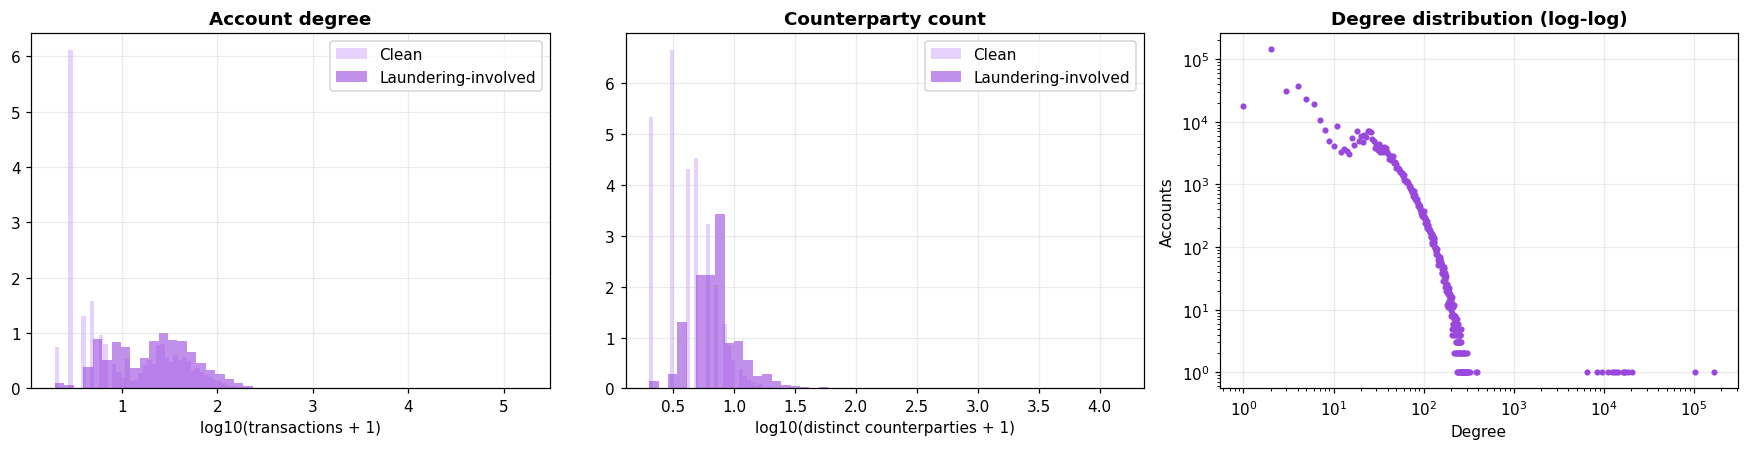

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))

for label, colour, name in [(False, LILAC, "Clean"), (True, PURPLE, "Laundering-involved")]:
    sub = acc[acc["Is Laundering Account"].eq(label)]
    if not len(sub):
        continue
    ax[0].hist(np.log10(sub["Degree"] + 1), bins=50, density=True, alpha=0.6,
               color=colour, label=name)
    ax[1].hist(np.log10(sub["Counterparties"] + 1), bins=50, density=True, alpha=0.6,
               color=colour, label=name)

ax[0].set_xlabel("log10(transactions + 1)"); ax[0].set_title("Account degree", fontweight="bold"); ax[0].legend()
ax[1].set_xlabel("log10(distinct counterparties + 1)"); ax[1].set_title("Counterparty count", fontweight="bold"); ax[1].legend()

deg = acc["Degree"].value_counts().sort_index()
ax[2].loglog(deg.index, deg.values, marker=".", ls="none", color=PURPLE)
ax[2].set_xlabel("Degree"); ax[2].set_ylabel("Accounts")
ax[2].set_title("Degree distribution (log-log)", fontweight="bold")
plt.tight_layout(); plt.show()

In [23]:
# Hub accounts: the heaviest senders, and whether they are laundering-involved.
hubs = acc.nlargest(15, "Degree")[
    ["Account ID", "Degree", "Sent_Count", "Recv_Count",
     "Counterparties", "Laundering Rows", "Is Laundering Account"]
]
display(hubs)

print("\nExtreme in/out imbalance — accounts that mostly collect, or mostly disburse:")
busy = acc[acc["Degree"] >= 10].copy()
busy["Out Share"] = busy["Sent_Count"] / busy["Degree"]
display(pd.concat([
    busy.nlargest(5, "Out Share")[["Account ID", "Degree", "Out Share", "Is Laundering Account"]],
    busy.nsmallest(5, "Out Share")[["Account ID", "Degree", "Out Share", "Is Laundering Account"]],
]))

,Account ID,Degree,Sent_Count,Recv_Count,Counterparties,Laundering Rows,Is Laundering Account
0,100428660,169756.0,168672.0,1084.0,14775.0,243.0,True
1,1004286A8,103671.0,103018.0,653.0,9174.0,158.0,True
11,100428978,20647.0,20497.0,150.0,1851.0,29.0,True
2,1004286F0,18771.0,18663.0,108.0,1630.0,21.0,True
4,100428780,17381.0,17264.0,117.0,1482.0,21.0,True
12,1004289C0,16926.0,16794.0,132.0,1500.0,13.0,True
6,100428810,16540.0,16426.0,114.0,1452.0,26.0,True
5,1004287C8,14277.0,14174.0,103.0,1237.0,16.0,True
3,100428738,13854.0,13756.0,98.0,1187.0,23.0,True
14,100428A51,13101.0,13073.0,28.0,1161.0,18.0,True



Extreme in/out imbalance — accounts that mostly collect, or mostly disburse:


,Account ID,Degree,Out Share,Is Laundering Account
183,8000644D0,103.0,1.0,False
187,800065110,78.0,1.0,True
290,800076731,10.0,1.0,False
294,800077540,98.0,1.0,False
296,800077AA0,97.0,1.0,False
1288,800124300,20.0,0.0,False
1289,8001243A0,14.0,0.0,False
1616,800156DC0,11.0,0.0,False
2177,8001B1E30,20.0,0.0,False
3621,80029B621,10.0,0.0,False


<a id="13-structuring"></a>
## <span style="color:#9947dc">13. Structuring signals</span>

**Why.** Structuring means breaking a large sum into many smaller transfers, often at
round numbers or just under a reporting threshold. It is one of the best-known laundering
techniques, so it is worth testing whether this dataset simulates it before we spend time
building features for it.

**How.** Two checks. First, how often amounts land on round values, compared between
classes. Second, how often an account sends the exact same amount repeatedly.

**What the output shows — both come back negative, which is useful.**

Round numbers are equally rare in both classes:

| Check | Legitimate | Laundering |
|---|---|---|
| Multiple of 10 | 0.122% | 0.116% |
| Multiple of 100 | 0.012% | 0.019% |
| Multiple of 1000 | 0.001% | 0.000% |
| Whole number | 1.207% | 1.159% |

There is no difference. Amounts in this dataset are generated continuously, so round-sum
structuring simply is not simulated.

Repeated amounts are equally uninformative. 455,387 account-and-amount pairs repeat 3 or
more times, but only 566 of them (0.12%) involve any laundering at all. The repeats come
from a handful of very high-volume accounts doing ordinary business, not from layering.

**Conclusion: do not build round-number or repeated-amount features.** This cost two
cells to establish and saves building a feature family that would have contributed
nothing. Reporting a negative result here is worth more than leaving it untested.

In [24]:
display(eu.round_amount_profile(trans))
print("If laundering and legitimate rows round at the same rate, the generator does not")
print("simulate structuring and round-number features will not help. Worth knowing early.")

,Check,All %,Legitimate %,Laundering %
0,Multiple of 10,0.122,0.122,0.116
1,Multiple of 100,0.012,0.012,0.019
2,Multiple of 1000,0.001,0.001,0.000
3,Whole number,1.207,1.207,1.159


If laundering and legitimate rows round at the same rate, the generator does not
simulate structuring and round-number features will not help. Worth knowing early.


In [25]:
rep = eu.repeated_amounts(trans, min_repeats=3)
print(f"(account, amount) pairs repeated 3+ times: {len(rep):,}")
display(rep.head(15))

if len(rep):
    with_l = rep[rep["Laundering"] > 0]
    print(f"\nOf those, pairs involving laundering: {len(with_l):,} "
          f"({len(with_l) / len(rep) * 100:.2f}%)")

(account, amount) pairs repeated 3+ times: 455,387


,Account,Amount Paid,Repeats,Laundering,Counterparties
0,100428660,31.48,44,0,5
1,100428660,37.29,40,1,4
2,100428660,10.06,37,0,4
3,1004286A8,88.08,34,0,4
4,100428660,191.71,34,0,4
5,100428660,41.95,34,0,4
6,100428660,101.19,30,0,3
7,100428660,165.56,30,0,3
8,100428660,52.71,30,0,3
9,100428660,459.71,30,0,3



Of those, pairs involving laundering: 566 (0.12%)


<a id="12b-hubs"></a>
## <span style="color:#9947dc">14. Hub accounts</span>

**Why.** A handful of accounts in this dataset transact hundreds of thousands of times,
and they also touch laundering. If they are left in, they could single-handedly create
the appearance that "high activity means laundering" in section 12. We need to check
whether that finding survives without them.

**How.** Flag accounts in the top 0.01% by transaction count, or with 500+ distinct
counterparties. Look at who they are. Then re-run the section 12 comparison with them
removed.

**What the output shows.**

**55 hub accounts**, 0.011% of all accounts, defined by a threshold of 260 transactions.

They are extraordinary. The largest, `100428660`, makes 168,672 payments to 14,775
distinct counterparties — **1.67% of every row in the file, from one account.** The
second, `1004286A8`, is another 1.02%. For comparison, a normal account makes 6
transactions in total.

**All fifteen of the largest belong to the same bank: "Oasis Thrift".** Their account
numbers are sequential (`100428660`, `1004286A8`, `1004286F0`, ...). These are not
customers — they are clearing or settlement accounts, and the entity names attached to
them (`Sole Proprietorship #41`, `Country #1`) look like filler rather than real
ownership.

**The important result: the section 12 finding survives.** With hubs excluded, the
medians are unchanged — 6 against 22 transactions, 3 against 6 counterparties, 2 against
13 received. Identical to the figures including hubs.

That is because we compared medians, which are not moved by 55 extreme values out of
515,080. The network signal is real and not an artefact of these accounts.

**But still handle them in preprocessing.** Any feature based on an *average* rather
than a median will be dominated by them, and `100428660` alone would distort any
normalisation. Flag them, and consider excluding them or capping their values.

In [26]:
acc, hub_info = eu.identify_hubs(acc)
display(pd.Series(hub_info).rename("Value").to_frame())

print("\nWho the biggest accounts are")
display(eu.hub_detail(acc, trans, top_n=15))

print("\nNetwork comparison — with hubs and without")
display(eu.hub_impact(acc))

,Value
Degree threshold,260.00000
Quantile used,0.99990
Min counterparties,500.00000
Hub accounts,55.00000
Hub share of accounts %,0.01068



Who the biggest accounts are


,Account ID,Degree,Sent_Count,Recv_Count,Counterparties,Laundering Rows,Is Laundering Account,Bank,Entity,Share of all rows %
0,100428660,169756.0,168672.0,1084.0,14775.0,243.0,True,Oasis Thrift,Sole Proprietorship #41,1.671
1,1004286A8,103671.0,103018.0,653.0,9174.0,158.0,True,Oasis Thrift,Partnership #2370,1.021
2,100428978,20647.0,20497.0,150.0,1851.0,29.0,True,Oasis Thrift,Sole Proprietorship #36613,0.203
3,1004286F0,18771.0,18663.0,108.0,1630.0,21.0,True,Oasis Thrift,Partnership #30358,0.185
4,100428780,17381.0,17264.0,117.0,1482.0,21.0,True,Oasis Thrift,Sole Proprietorship #31648,0.171
5,1004289C0,16926.0,16794.0,132.0,1500.0,13.0,True,Oasis Thrift,Sole Proprietorship #37508,0.167
6,100428810,16540.0,16426.0,114.0,1452.0,26.0,True,Oasis Thrift,Sole Proprietorship #10935,0.163
7,1004287C8,14277.0,14174.0,103.0,1237.0,16.0,True,Oasis Thrift,Corporation #31479,0.141
8,100428738,13854.0,13756.0,98.0,1187.0,23.0,True,Oasis Thrift,Corporation #29514,0.136
9,100428A51,13101.0,13073.0,28.0,1161.0,18.0,True,Oasis Thrift,Country #1,0.129



Network comparison — with hubs and without


,All accounts | clean,All accounts | laundering,Hubs excluded | clean,Hubs excluded | laundering
Degree,6.0,22.0,6.0,22.0
Counterparties,3.0,6.0,3.0,6.0
Sent_Count,2.0,4.0,2.0,4.0
Recv_Count,2.0,13.0,2.0,13.0


<a id="12c-jurisdiction"></a>
## <span style="color:#9947dc">15. Countries and cross-border flow</span>

**Why.** Cross-border movement is the most widely used risk indicator in real
anti-money-laundering work — it is the basis of the FATF high-risk jurisdiction lists
that banks actually screen against. A financial-crime audience will look for this first,
and our earlier analysis had nothing on it.

**How.** Bank names in this dataset encode a country for foreign institutions
(`Portugal Bank #4507`, `China Bank #561`) while domestic ones use city or brand names
(`National Bank of Laramie`, `Oasis Thrift`). We extract the country from the name
pattern, then measure risk by sender country, receiver country, and country pair.

The first cell is a safety check: it lists every prefix found and whether our country
list recognises it. That exists so a real country cannot silently fall into
"Domestic/Other" without us noticing.

**What the check caught.** Two things, both now fixed in `eda_utils.py`:

- Six real countries were missing from our list: **Slovakia (1,534 accounts), Croatia
  (1,080), Lithuania (991), Slovenia (653), Estonia (176) and Latvia (157)**. They were
  being counted as domestic.
- **"Crytpo" (14,358 accounts)** — the misspelling is in the source data. These are
  crypto exchanges, not a country, and they now get their own label rather than being
  mixed in with domestic banks.

Re-run this section after updating `eda_utils.py` and the numbers below will shift
slightly. The headline result will not change.

**What the output shows — this is a strong, genuine finding.**

**Cross-border transfers are 27.4% of volume but 59.7% of all laundering.** The rate is
**0.2220% cross-border against 0.0566% same-jurisdiction — roughly 4 times higher.**

Unlike the payment-format result, this matches how laundering genuinely works, so it is
a finding we can defend as a domain result rather than a dataset artefact.

By sending country, **Saudi Arabia is the clear outlier at 0.4513%**, about five times
the typical country rate, followed by Finland (0.2397%) and Spain (0.1354%). Most other
countries sit between 0.08% and 0.11%. This lines up with the Saudi Riyal currency
result in section 10 — the same flows seen two different ways.

The country-pair table shows something more interesting still: **specific corridors**,
and some of them run in both directions.

| Route | Transactions | Rate |
|---|---|---|
| UK → Domestic | 2,473 | 2.10% |
| Saudi Arabia → Israel | 3,503 | 1.77% |
| Canada → Domestic | 2,021 | 1.63% |
| Spain → Finland | 1,533 | 1.37% |
| Finland → Spain | 3,286 | 0.94% |
| Israel → Saudi Arabia | 6,314 | 0.71% |

Saudi Arabia ↔ Israel and Spain ↔ Finland are both elevated in *both* directions. Money
moving back and forth along a fixed route at 10 to 20 times the baseline rate is what a
laundering corridor looks like. For our system this is directly useful: "which
jurisdictions does this case touch, and is this a known corridor" is exactly the kind of
question an investigation tool should answer.

In [27]:
census = eu.bank_prefix_census(accounts["Bank Name"], top=30)
display(census)
print("Prefixes not recognised as countries are treated as Domestic/Other.")
print("If a real country is missing, add it to eu.COUNTRY_HINTS and re-run.")

,Accounts,Recognised as country,Mapped to
Bank Name,,,
Germany,32733,True,Germany
Switzerland,24949,True,Switzerland
China,23489,True,China
France,21416,True,France
India,19359,True,India
Israel,19248,True,Israel
UK,17982,True,UK
Italy,17433,True,Italy
Japan,17156,True,Japan


Prefixes not recognised as countries are treated as Domestic/Other.
If a real country is missing, add it to eu.COUNTRY_HINTS and re-run.


In [28]:
jur = eu.jurisdiction_analysis(trans)

print("Cross-border vs same-jurisdiction")
display(jur["by_cross_border"])

print("\nBy sender jurisdiction")
display(jur["by_sender"])

print("\nBy receiver jurisdiction")
display(jur["by_receiver"])

print("\nRiskiest country pairs (>= 1,000 transactions)")
display(jur["riskiest_pairs"])

Cross-border vs same-jurisdiction


,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Flow,,,,,
Cross-border,1424964,3124,0.2192,60.34,28.06
Same jurisdiction,3653381,2053,0.0562,39.66,71.94



By sender jurisdiction


,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Sender Country,,,,,
Saudi Arabia,62265,281,0.4513,5.43,1.23
Slovenia,3201,10,0.3124,0.19,0.06
Finland,35463,85,0.2397,1.64,0.70
Spain,111538,151,0.1354,2.92,2.20
Belgium,41134,51,0.1240,0.99,0.81
Portugal,31084,35,0.1126,0.68,0.61
China,261709,285,0.1089,5.51,5.15
Slovakia,13079,14,0.1070,0.27,0.26
Austria,38534,41,0.1064,0.79,0.76



By receiver jurisdiction


,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Receiver Country,,,,,
Finland,22135,96,0.4337,1.85,0.44
Saudi Arabia,76829,280,0.3644,5.41,1.51
Spain,131689,191,0.1450,3.69,2.59
Belgium,51257,64,0.1249,1.24,1.01
Germany,329456,357,0.1084,6.90,6.49
France,198770,215,0.1082,4.15,3.91
Italy,159782,172,0.1076,3.32,3.15
Greece,35041,36,0.1027,0.70,0.69
Domestic/Other,1978325,2002,0.1012,38.67,38.96



Riskiest country pairs (>= 1,000 transactions)


Transactions  Laundering  Rate %
Sender Country Receiver Country                                  
Japan          Domestic/Other            1896          49  2.5844
UK             Domestic/Other            2357          49  2.0789
Saudi Arabia   Israel                    3503          62  1.7699
Canada         Domestic/Other            1990          33  1.6583
Netherlands    Domestic/Other            1017          16  1.5733
Spain          Domestic/Other            3125          43  1.3760
               Finland                   1533          21  1.3699
France         Domestic/Other            3930          49  1.2468
Australia      Domestic/Other            2398          28  1.1676
Germany        Domestic/Other            8912          94  1.0548
Finland        Domestic/Other            1550          16  1.0323
Italy          Domestic/Other            3540          34  0.9605
Finland        Spain                     3286          31  0.9434
Domestic/Other Finland                   3286          29  0.8825
China          Domestic/Other           10447          88  0.8423
Israel         Saudi Arabia              6314          45  0.7127
China          Finland                   1151           7  0.6082
France         China                     1158           7  0.6045
Russia         Domestic/Other            4385          22  0.5017
India          Domestic/Other            7042          34  0.4828

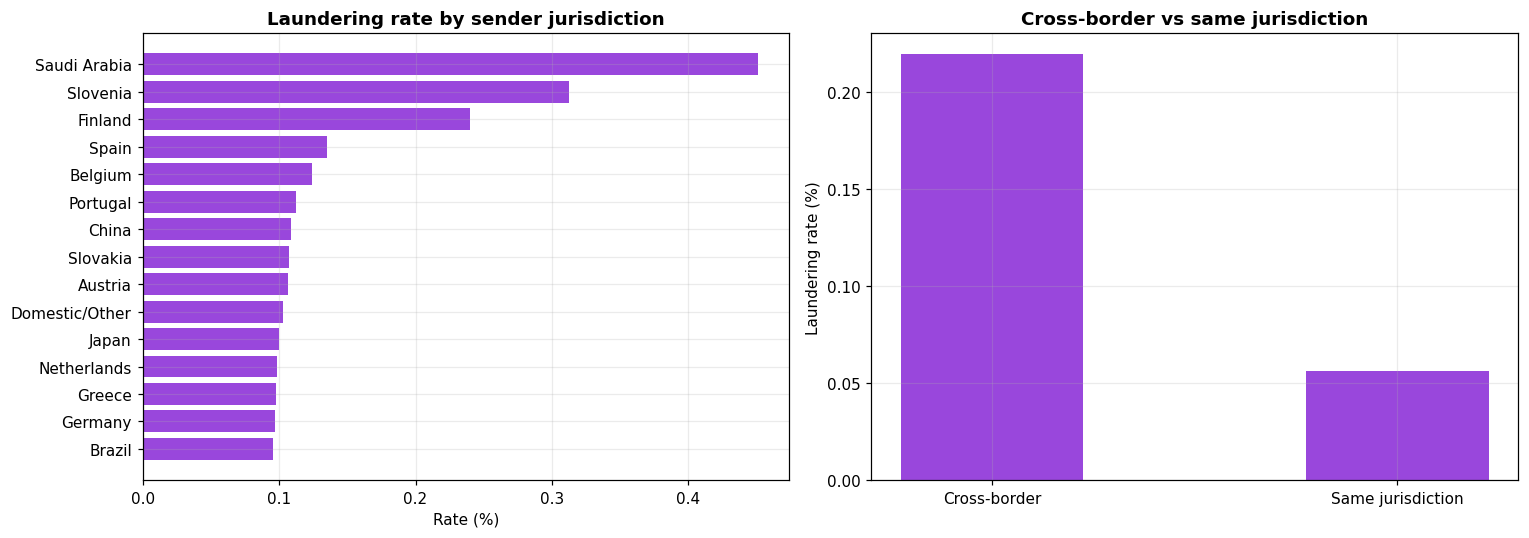

In [29]:
send_risk = jur["by_sender"].head(15).sort_values("Rate %")
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].barh(send_risk.index.astype(str), send_risk["Rate %"], color=PURPLE)
ax[0].set_title("Laundering rate by sender jurisdiction", fontweight="bold")
ax[0].set_xlabel("Rate (%)")

cb = jur["by_cross_border"]
ax[1].bar(cb.index.astype(str), cb["Rate %"], color=PURPLE, width=0.45)
ax[1].set_title("Cross-border vs same jurisdiction", fontweight="bold")
ax[1].set_ylabel("Laundering rate (%)")
plt.tight_layout(); plt.show()

<a id="12d-entities"></a>
## <span style="color:#9947dc">16. Entities</span>

**Why.** An entity is the owner behind an account, and one entity can hold several
accounts. We wanted to test a specific hypothesis: moving money between accounts you
already control is a classic layering step, so same-entity transfers might be high risk.

**How.** Count accounts per entity. Extract the entity type from names like
`Corporation #34854`. Then compare transfers that stay inside one entity against those
that cross between entities.

**What the output shows.**

**Entities hold multiple accounts, but most hold one.** 166,207 entities, mean 3.12
accounts each, median 1. 102,689 entities (62%) have exactly one account. The
distribution has a long tail — one entity controls 7,820 accounts.

**The hypothesis was wrong, and the opposite is true.** Same-entity transfers are
661,334 transactions (13.0% of volume) with only **35 laundering cases — a rate of
0.0053%**. Different-entity transfers run at 0.1164%. Same-entity transfers are
**22 times safer**, not riskier.

This is still a useful feature, just with the opposite sign from what we expected: a
transfer between two accounts of the same owner is strong evidence of *legitimate*
internal movement. Section 19 explains part of why — most of these are self-transfers.

**Entity type barely matters.** Individual 0.1388%, Corporation 0.1265%, Partnership
0.1013%, Sole Proprietorship 0.0867%, Country 0.0337%, Direct 0%. The spread between the
common types is about 1.5x — far weaker than payment format (20x) or cross-border (4x).
Worth including as a low-weight categorical feature, not worth emphasising.

Two entity types we did not expect appear in the data: "Individual" (4,323 transactions)
and "Direct" (503). Both are too rare to draw conclusions from.

In [30]:
span, dist = eu.accounts_per_entity(accounts)
print("Accounts controlled per entity")
display(span.to_frame("Accounts per entity"))
print("\nMost common counts")
display(dist.rename("Entities").to_frame())

Accounts controlled per entity


,Accounts per entity
count,166207.00
mean,3.12
std,38.99
min,1.00
25%,1.00
50%,1.00
75%,3.00
max,7820.00



Most common counts


,Entities
Accounts,
1,102689
2,15732
3,11443
4,9840
5,8573
6,6173
7,4271
8,2524
9,1420


In [31]:
ent = eu.entity_analysis(trans)

print("Transfers inside one entity vs between entities")
display(ent["same_entity"])

print("\nBy sender entity type")
display(ent["by_sender_type"])

print("\nLaundering rate by entity type pair (%)")
display(ent["type_pair_rate"])

Transfers inside one entity vs between entities


,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Relationship,,,,,
Different entity,4417011,5142,0.1164,99.32,86.98
Same entity,661334,35,0.0053,0.68,13.02



By sender entity type


,Transactions,Laundering,Rate %,Share of Laundering %,Share of Volume %
Sender Entity Type,,,,,
Individual,4323,6,0.1388,0.12,0.09
Corporation,1409470,1783,0.1265,34.44,27.75
Partnership,1781367,1805,0.1013,34.87,35.08
Sole Proprietorship,1790830,1552,0.0867,29.98,35.26
Country,91852,31,0.0337,0.60,1.81
Direct,503,0,0.0000,0.00,0.01



Laundering rate by entity type pair (%)


Receiver Entity Type,Corporation,Country,Direct,Individual,Partnership,Sole Proprietorship
Sender Entity Type,,,,,,
Corporation,0.1002,0.1880,0.0,0.0,0.1515,0.1366
Country,0.0000,0.0225,NaN,NaN,0.0483,0.0594
Direct,0.0000,NaN,0.0,0.0,0.0000,0.0000
Individual,0.0776,NaN,0.0,0.0,0.2588,0.1842
Partnership,0.1246,0.0549,0.0,0.0,0.0843,0.1069
Sole Proprietorship,0.1061,0.0000,0.0,0.0,0.0970,0.0668


<a id="12e-passthrough"></a>
## <span style="color:#9947dc">17. Pass-through behaviour</span>

**Why.** This is the question an investigator actually asks: did the money stop here, or
did it pass straight through? An account that receives funds and forwards them within
minutes is behaving like a conduit. An account that receives money and keeps it is
behaving like a destination. Nothing in the earlier analysis measured this.

**How.** For every outgoing transfer, find that account's most recent *incoming*
transfer within the previous 24 hours and compare the two amounts. If the outgoing
amount is within 10% of what just arrived, we call it a pass-through.

We also record **dwell time** — the gap between money arriving and leaving again.

Implementation note: this is done with `merge_asof` on integer account codes rather than
by comparing every pair of transfers, which keeps it to about 15 seconds on 5 million
rows instead of hours.

**What the output shows — this is the strongest behavioural signal in the notebook.**

| | Legitimate | Laundering |
|---|---|---|
| Transfers | 5,073,168 | 5,177 |
| Pass-throughs | 648,301 | 2,119 |
| **Pass-through rate** | **12.78%** | **40.93%** |

Laundering transfers forward incoming money **3.2 times as often** as normal ones.

Dwell time is even sharper:

| | Legitimate | Laundering |
|---|---|---|
| Median | 5.08 hours | **0.00 hours** |
| 25th percentile | 0.25 hours | 0.00 hours |
| 75th percentile | 11.92 hours | 5.28 hours |
| Mean | 6.98 hours | 3.66 hours |

**More than half of laundering transfers send the money out in the same minute it
arrives.** Normal traffic holds funds for about five hours on average.

**Why this matters more than the other signals.** Payment format is a stronger separator
numerically, but we established in section 8 that it is an artefact of how the data was
built. Pass-through behaviour is different: fast forwarding of received funds is what
layering genuinely *is*, in this dataset and in real life. It is the feature most likely
to survive contact with real data, and it should go into the model and into the
investigation tool suite.

In [32]:
pt, pt_summary, dwell = eu.passthrough(trans, window_hours=24, tolerance=0.10)

print("Pass-through rate by class")
display(pt_summary)

print("\nDwell time in hours — money in to money out")
display(dwell)

Pass-through rate by class


,Transfers,Passthroughs,Passthrough %
Is Laundering,,,
0,5073168,648301,12.779
1,5177,2119,40.931



Dwell time in hours — money in to money out


,count,mean,std,min,25%,50%,75%,max
Is Laundering,,,,,,,,
0,3390608.0,6.983,6.909,0.0,0.25,5.083,11.917,24.0
1,3678.0,3.655,6.168,0.0,0.00,0.000,5.283,24.0


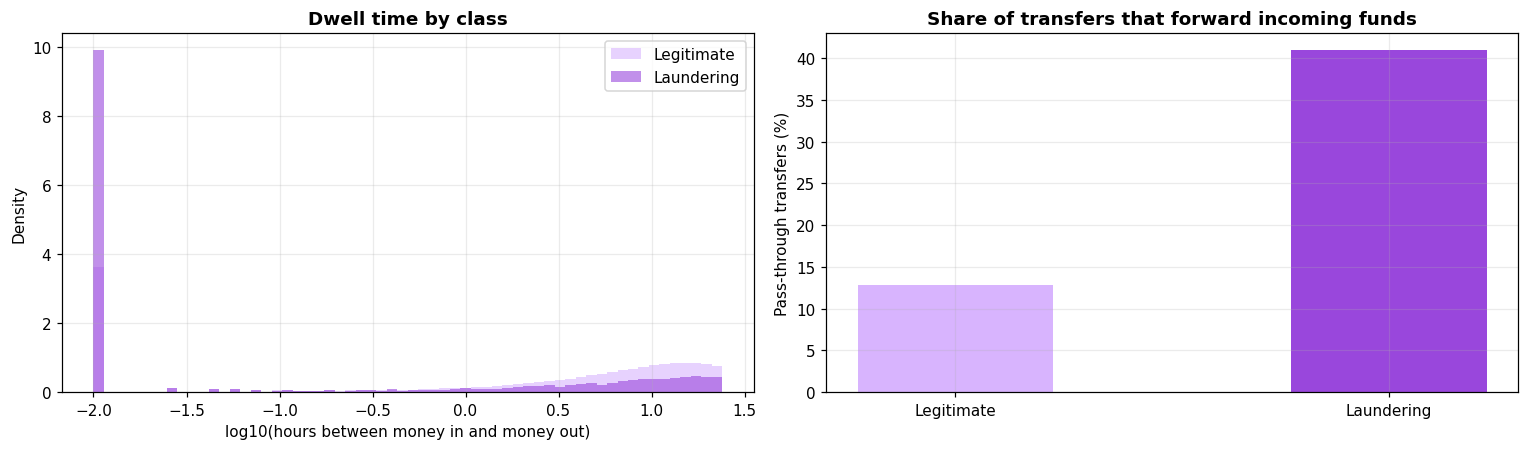

In [33]:
d = pt.dropna(subset=["Dwell (hours)"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for label, colour, name in [(0, LILAC, "Legitimate"), (1, PURPLE, "Laundering")]:
    vals = d.loc[d["Is Laundering"].eq(label), "Dwell (hours)"]
    if len(vals):
        ax[0].hist(np.log10(vals + 0.01), bins=60, density=True, alpha=0.6,
                   color=colour, label=name)
ax[0].set_xlabel("log10(hours between money in and money out)")
ax[0].set_ylabel("Density"); ax[0].legend()
ax[0].set_title("Dwell time by class", fontweight="bold")

rates = pt_summary["Passthrough %"]
ax[1].bar(["Legitimate", "Laundering"][:len(rates)], rates.values,
          color=[LILAC, PURPLE][:len(rates)], width=0.45)
ax[1].set_ylabel("Pass-through transfers (%)")
ax[1].set_title("Share of transfers that forward incoming funds", fontweight="bold")
plt.tight_layout(); plt.show()

<a id="12f-lifetime"></a>
## <span style="color:#9947dc">18. How long accounts stay active</span>

**Why.** Accounts used to move illicit funds are often short-lived — they appear, pass
money through, and go quiet. We wanted to test whether that holds here.

**How.** For each account, record the first and last time it appears in any transaction,
sending or receiving, and measure the span between them.

**What the output shows — weak, and not in the direction we expected.**

Median active span is 8.05 days for clean accounts and 8.92 days for laundering-involved
ones. Essentially the same, and if anything laundering accounts are active slightly
*longer*.

The quartiles are more interesting than the medians. Clean accounts have a 25th
percentile of 1.26 days — a large share of ordinary accounts appear briefly and vanish.
Laundering-involved accounts have a 25th percentile of 8.08 days, so they are
consistently present across the window. That makes sense given schemes run a median of
3.11 days and often involve accounts across several schemes.

Transaction counts separate the groups much better than span does: median 6 events for
clean accounts against 22 for laundering-involved — but that is the same information
already captured in section 12.

**Conclusion: do not build an account-age feature.** The short-lived-mule pattern is not
simulated in this dataset. Another negative result that saves work, and another one worth
stating in the report rather than quietly dropping.

Is Laundering Account      False      True 
Span (days) count      508723.00    6357.00
            mean            6.16       8.39
            std             3.75       2.58
            min             0.00       0.00
            25%             1.26       8.08
            50%             8.05       8.92
            75%             8.99       9.61
            max            10.00      17.68
Events      count      508723.00    6357.00
            mean           18.68     102.75
            std            25.65    2576.66
            min             1.00       1.00
            25%             2.00       8.00
            50%             6.00      22.00
            75%            27.00      41.00
            max           394.00  169756.00

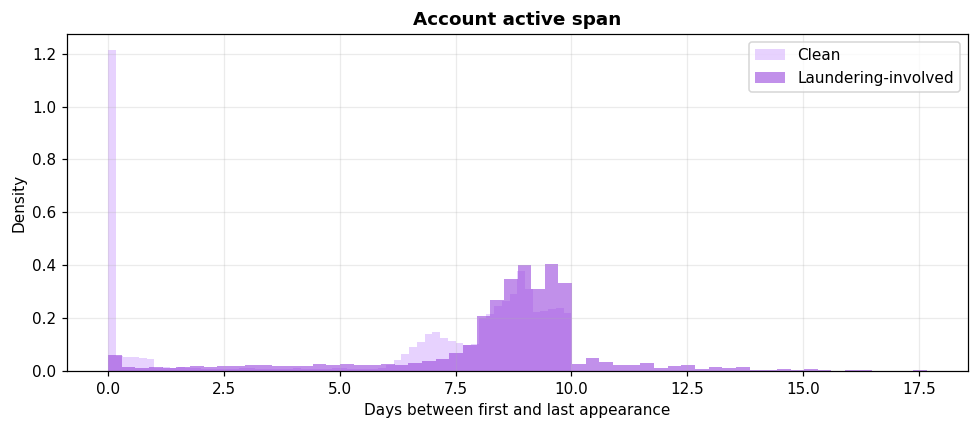

In [34]:
life = eu.account_lifetime(trans)
display(eu.lifetime_contrast(life))

fig, ax = plt.subplots(figsize=(9, 4))
for label, colour, name in [(False, LILAC, "Clean"), (True, PURPLE, "Laundering-involved")]:
    vals = life.loc[life["Is Laundering Account"].eq(label), "Span (days)"]
    if len(vals):
        ax.hist(vals, bins=60, density=True, alpha=0.6, color=colour, label=name)
ax.set_xlabel("Days between first and last appearance")
ax.set_ylabel("Density"); ax.legend()
ax.set_title("Account active span", fontweight="bold")
plt.tight_layout(); plt.show()

<a id="13b-integrity"></a>
## <span style="color:#9947dc">19. Integrity checks</span>

**Why.** Four checks that the earlier analysis never ran, each of which changes something
downstream.

**What the output shows.**

**1. Self-transfers: 591,212 rows, 11.6% of the entire file.** These are transactions
where the sending and receiving account are the same. They contain 11 laundering cases
out of 5,177.

The breakdown by format explains a puzzle from section 8:

| Format | Rows | Self-transfers | Share |
|---|---|---|---|
| Reinvestment | 481,056 | 481,056 | **100%** |
| Bitcoin | 146,091 | 26,317 | 18.0% |
| ACH | 600,797 | 71,347 | 11.9% |
| Wire | 171,855 | 795 | 0.5% |

**Every single Reinvestment transaction is an account paying itself.** That is why
Reinvestment has zero laundering — it is not a transfer between parties at all, it is an
accounting entry. The same explanation partly covers Wire.

This is a real preprocessing decision: 11.6% of the file is arguably not transactional
data. It also explains the section 16 result — same-entity transfers look safe largely
because most of them are self-transfers.

**2. Zero amounts: none.** The minimum of 0.00 in the earlier summary tables was just
rounding; the true minimum is 0.000001.

**3. Duplicate rows: 9.** Negligible.

**4. Bank names do not map one-to-one to bank IDs.** 20,053 distinct bank names but
30,470 distinct bank IDs. **468 bank names map to more than one ID, and one name maps to
48 of them** — "Bank of Billings" and "First Bank of Miami" both have 48 separate IDs.

The relationship only breaks in one direction: no ID maps to multiple names.

**Consequence:** grouping by `Bank ID` splits a single bank into dozens of fragments.
Any bank-level feature — transaction counts per bank, risk score per bank — must group
by name, or by a cleaned identifier, not by the raw ID. This also affects section 15,
since country is derived from the name rather than the ID, which is the correct choice.

In [35]:
checks, self_by_format, bank_consistency, worst_names = eu.integrity_checks(trans, accounts)

display(checks)

print("\nSelf-transfers by payment format")
display(self_by_format)

print("\nBank name vs bank ID consistency")
display(pd.Series(bank_consistency).rename("Value").to_frame())

print("\nBank names split across the most IDs")
display(worst_names.rename("Distinct bank IDs").to_frame())

,Check,Rows,% of file,Laundering
0,Self-transfers (Account == Account.1),591212,11.6418,11
1,Amount Paid == 0,0,0.0000,0
2,Amount Received == 0,0,0.0000,0
3,Exact duplicate rows,9,0.0002,<NA>



Self-transfers by payment format


,Rows,Self_Transfers,Self %
Payment Format,,,
ACH,600797,71347,11.88
Bitcoin,146091,26317,18.01
Cash,490891,1455,0.3
Cheque,1864331,6066,0.33
Credit Card,1323324,4176,0.32
Reinvestment,481056,481056,100.0
Wire,171855,795,0.46



Bank name vs bank ID consistency


,Value
Distinct bank names,20053
Distinct bank IDs,30470
Names mapping to >1 ID,468
Max IDs for one name,48
IDs mapping to >1 name,0



Bank names split across the most IDs


,Distinct bank IDs
Bank Name,
Bank of Billings,48
First Bank of Miami,48
National Bank of Fairfield,47
National Bank of Los Angeles,46
National Bank of Sacramento,46
Savings Bank of Newport,45
First Bank of Danbury,44
First Bank of the East,44
National Bank of Miami,44


<a id="13c-examples"></a>
## <span style="color:#9947dc">20. What a laundering attempt actually looks like</span>

**Why.** Two reasons. First, "GATHER-SCATTER: 51 attempts, 716 transfers" conveys
nothing about shape — a reader needs to see one. Second, and more practically, the case
file our system produces should contain roughly this: the accounts involved, the
transfers between them, and the order they happened in. So these diagrams double as a
specification for the output format.

**How.** For each of the 8 topologies, pick one attempt of about average size and draw
it as a network: each circle is an account (labelled with the last 4 characters of its
number), each arrow is a transfer. Then print the underlying transfer list for one of
them.

We drew these by hand with matplotlib rather than adding networkx, to avoid a dependency
the whole group would have to install for eight pictures.

**What the output shows.** The eight topologies are visibly different structures:
fan-outs spray from one account, fan-ins collect into one, cycles return to their
origin, stacks chain through intermediaries, and gather-scatter does both in sequence.

The transfer list makes one concrete. **GATHER-SCATTER attempt 307**: 8 transfers over
6.09 days, headed `Max 2-degree Fan-In`.

- Two accounts pay **into** `801E11270`: 12,481.21 EUR on 9 September, then 12,983.78
  EUR on 12 September
- That same account then pays **out** six times over the next three days: 2,067.37 EUR,
  13,889.75 CHF, 2,289.07 USD, 642,656.11 INR, 1,021.97 EUR, 628,969.09 JPY

Gather, then scatter — money collected into one account and dispersed from it.

Two details worth noticing. The outgoing transfers use **five different currencies**
where the incoming ones were both Euro. And the amounts are wildly uneven, from 1,021 to
642,656, so this is not simple splitting of a known sum. Both make the scheme harder to
spot with amount-matching rules alone — and both are things an investigation agent would
need to narrate when explaining the case to a human reviewer.

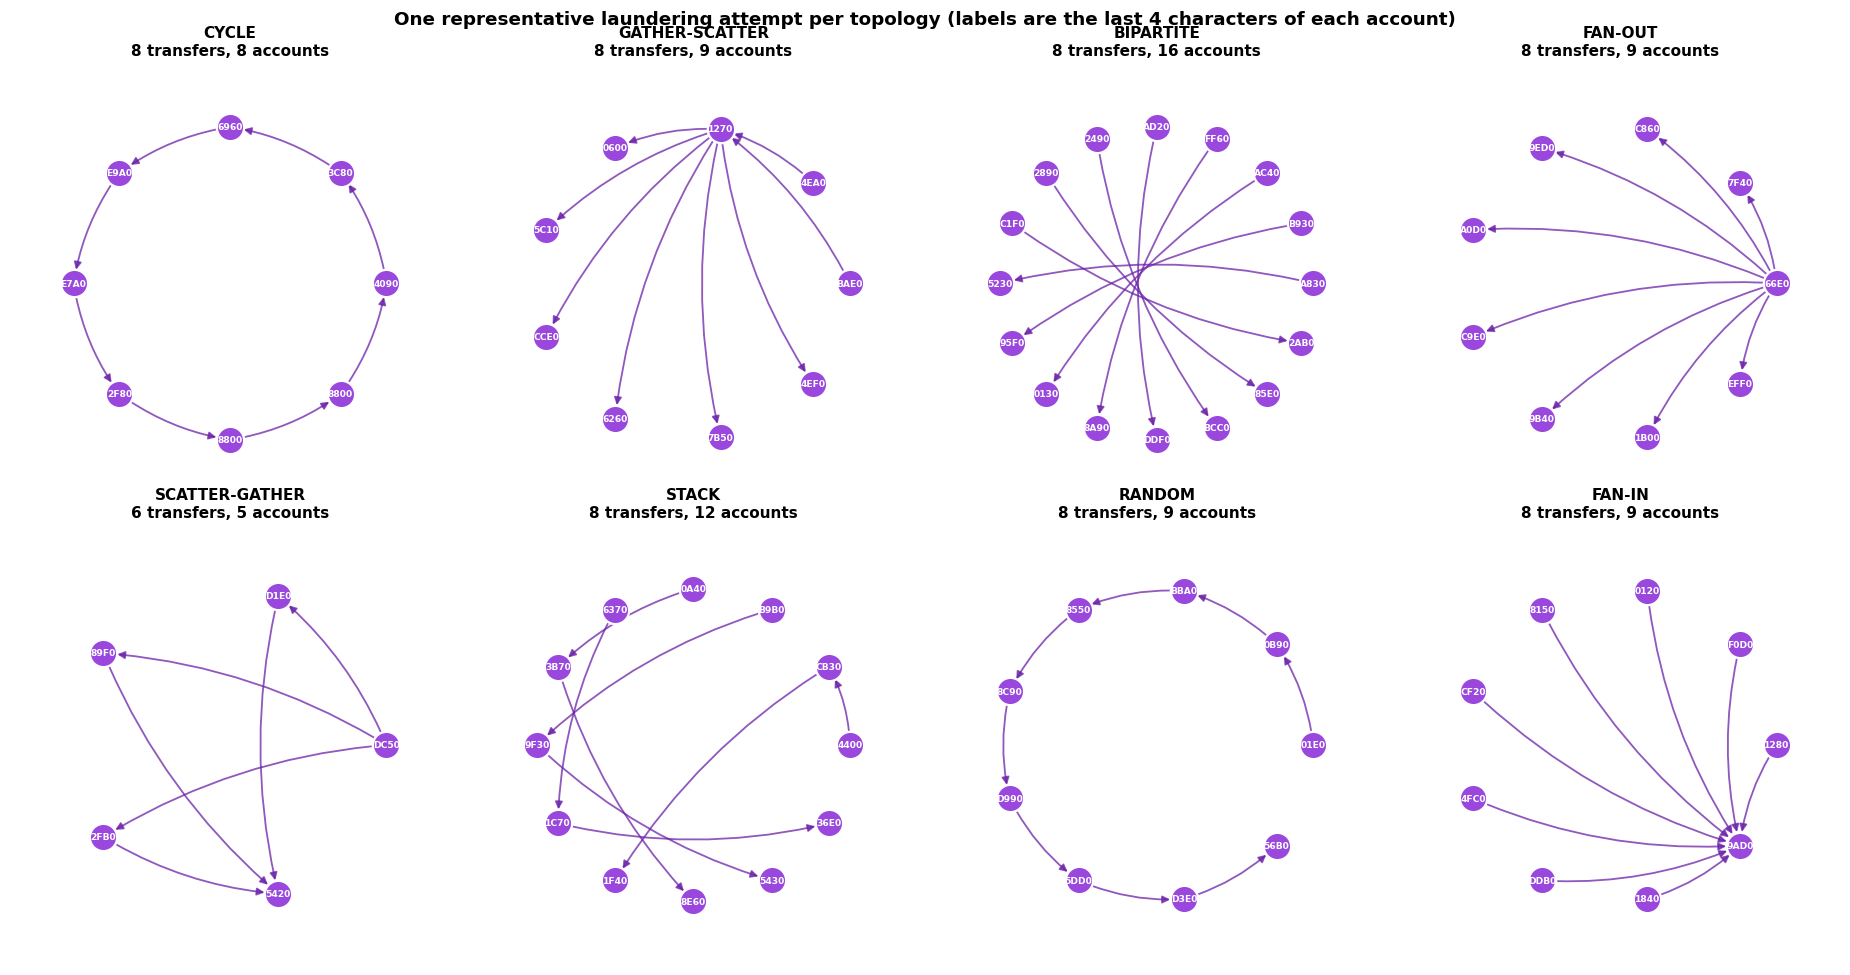

In [36]:
types = profile["Pattern Type"].value_counts().index.tolist()
fig, axes = plt.subplots(2, 4, figsize=(17, 9))

examples = {}
for ax, ptype in zip(axes.flatten(), types):
    best, rows = eu.pick_example_attempt(patterns, profile, ptype, target_rows=8)
    if rows is None:
        ax.axis("off"); continue
    examples[ptype] = (best, rows)
    eu.draw_attempt(rows, f"{ptype}\n{int(best['Rows'])} transfers, "
                          f"{int(best['Distinct Accounts'])} accounts", ax)

for ax in axes.flatten()[len(types):]:
    ax.axis("off")
fig.suptitle("One representative laundering attempt per topology "
             "(labels are the last 4 characters of each account)",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

In [37]:
# The transfer list behind one of those diagrams.
show_type = "GATHER-SCATTER" if "GATHER-SCATTER" in examples else types[0]
best, rows = examples[show_type]
print(f"{show_type} — attempt {int(best['Attempt ID'])}, "
      f"{int(best['Rows'])} transfers over {best['Span (days)']:.2f} days")
print(f"Header: {best['Header Meta']}")
display(rows[["Timestamp", "Account", "Account.1", "Amount Paid",
              "Payment Currency", "Payment Format"]].reset_index(drop=True))

GATHER-SCATTER — attempt 307, 8 transfers over 6.09 days
Header: Max 2-degree Fan-In


,Timestamp,Account,Account.1,Amount Paid,Payment Currency,Payment Format
0,2022-09-09 12:15:00,8002DBAE0,801E11270,12481.21,Euro,ACH
1,2022-09-12 04:08:00,800604EA0,801E11270,12983.78,Euro,ACH
2,2022-09-12 13:22:00,801E11270,8017A0600,2067.37,Euro,ACH
3,2022-09-14 08:05:00,801E11270,80FA75C10,13889.75,Swiss Franc,ACH
4,2022-09-14 08:41:00,801E11270,80C27CCE0,2289.07,US Dollar,ACH
5,2022-09-15 02:29:00,801E11270,804F86260,642656.11,Rupee,ACH
6,2022-09-15 10:05:00,801E11270,8093E7B50,1021.97,Euro,ACH
7,2022-09-15 14:26:00,801E11270,804324EF0,628969.09,Yen,ACH


<a id="14-leakage"></a>
## <span style="color:#9947dc">21. Can we split the data for training?</span>

**Why.** Section 6 showed that laundering attempts share accounts, and section 11 showed
the data effectively stops on 10 September. Both affect how we can split data into
training and test sets.

The risk is specific: if a laundering scheme has some transfers in training and others in
testing, the model sees part of the answer during training. Test recall then measures
memorisation, not detection, and the number we report is inflated.

**How.** For several candidate cutoff dates, measure how much data sits after the cutoff,
how many positives are in it, how many schemes get cut in half, and how many accounts
appear on both sides.

**What the output shows — no date-based cutoff works.**

| Cutoff | Rows after | Laundering after | Schemes cut |
|---|---|---|---|
| 10 Sep | 209,433 | 1,097 | 101 |
| 12 Sep | 712 | 423 | 67 |
| 14 Sep | 247 | 147 | 27 |
| 15 Sep | 126 | 77 | 13 |
| 16 Sep | 80 | 49 | 12 |

The tradeoff is impossible. A late cutoff cuts few schemes but leaves almost no data —
126 rows at 15 September, and those rows are 61% laundering. An early cutoff at
10 September leaves a usable 209,433 rows but cuts **101 of 370 schemes (27%)** in half,
and that held-out set is still contaminated by the post-10-September residue, running at
0.52% laundering instead of the true 0.1019%.

In [38]:
rows = []
for cut in ["2022-09-10", "2022-09-12", "2022-09-14", "2022-09-15", "2022-09-16"]:
    a = eu.attempts_straddling(profile, cut)
    b = eu.account_overlap_across_time(trans, cut)
    rows.append({
        "Cutoff": cut,
        "Rows before": b["Rows before"],
        "Rows after": b["Rows after"],
        "Laundering after": b["Laundering after"],
        "Attempts straddling": a["Attempts straddling"],
        "Shared accounts": b["Shared accounts"],
        "Shared % of after": b["Shared % of after"],
    })
display(pd.DataFrame(rows).set_index("Cutoff"))

,Rows before,Rows after,Laundering after,Attempts straddling,Shared accounts,Shared % of after
Cutoff,,,,,,
2022-09-10,4868912,209433,1097,101,147843,99.64
2022-09-12,5077633,712,423,67,463,98.93
2022-09-14,5078098,247,147,27,171,98.84
2022-09-15,5078219,126,77,13,87,98.86
2022-09-16,5078265,80,49,12,59,98.33


**What we recommend.**

Neither pure option works, so combine them:

1. **Discard everything from 11 September onward.** 1,575 rows, 655 of them laundering.
   It is not a time period, it is leftover output. Yes, this costs 12.6% of our positives
   — say so explicitly in the report, with the daily table from section 11 as the
   evidence.

2. **Also group by account**, because 100 accounts appear in multiple schemes. A date
   cutoff alone does not separate those.

The "shared accounts" column showing 98–99% is expected and is not itself leakage —
ordinary accounts legitimately keep transacting over time. The number that matters is the
schemes-cut column.

<a id="15-findings"></a>
## <span style="color:#9947dc">22. Findings and handoff</span>

The table below collects every candidate signal from this notebook in one place, so
preprocessing has a single thing to work from rather than twenty sections to re-read.
The ratio column is the laundering value divided by the legitimate value — higher means
better separation.

In [39]:
# Consolidated view of every candidate signal found above, so preprocessing has
# one table to work from instead of fourteen sections to re-read.
display(eu.candidate_features(trans, acc, life))

,Feature,Legitimate,Laundering,Ratio,Note
0,Amount Paid (median),1410.99,8667.21,6.14,Monetary scale
1,Cross-bank share %,86.37,98.01,1.13,Network routing
2,ACH share %,11.75,86.59,7.37,Channel - check for generator artefact
3,Account degree (median),6.00,22.00,3.67,Account level
4,Counterparties (median),3.00,6.00,2.00,Account level
5,Active span days (median),8.05,8.92,1.11,Account level


In [40]:
print("=" * 68)
print("HI-SMALL EDA — SUMMARY")
print("=" * 68)
print(f"Transactions           : {len(trans):,}")
print(f"Window                 : {trans['Timestamp'].min().date()} to {trans['Timestamp'].max().date()}")
print(f"Laundering rows        : {int(trans['Is Laundering'].sum()):,} "
      f"({trans['Is Laundering'].mean() * 100:.4f}%)")
print(f"  explained by patterns: {explained:,}")
print(f"  unexplained          : {flagged - explained:,}")
print(f"Laundering attempts    : {len(profile):,}")
print(f"  median transfers     : {profile['Rows'].median():.0f}")
print(f"  median span (days)   : {profile['Span (days)'].median():.2f}")
print(f"Distinct accounts      : {len(acc):,}")
print(f"  laundering-involved  : {int(acc['Is Laundering Account'].sum()):,}")
print(f"Accounts in >1 attempt : {len(shared):,}")
print(f"Unmatched account joins: {link_stats['Sender unmatched'] + link_stats['Receiver unmatched']}")
print("=" * 68)

HI-SMALL EDA — SUMMARY
Transactions           : 5,078,345
Window                 : 2022-09-01 to 2022-09-18
Laundering rows        : 5,177 (0.1019%)
  explained by patterns: 3,209
  unexplained          : 1,968
Laundering attempts    : 370
  median transfers     : 6
  median span (days)   : 3.11
Distinct accounts      : 515,080
  laundering-involved  : 6,357
Accounts in >1 attempt : 100
Unmatched account joins: 0


### Summary of what we found

**The data is clean but the labels are only partly explained.** No missing values, 9
duplicates in 5 million rows, every account resolves against the reference file. But only
62% of flagged transactions have a documented scheme behind them, and the unexplained 38%
are a structurally different population — every non-ACH positive is unexplained.

**Signals we trust, strongest first:**

1. **Pass-through behaviour** — 40.9% of laundering transfers forward money that just
   arrived, against 12.8% normally, with a median dwell time of 0 hours against 5.08.
   This is the one most likely to hold on real data.
2. **Cross-border movement** — 4x the laundering rate, with specific two-way corridors
   (Saudi Arabia ↔ Israel, Spain ↔ Finland) running 10 to 20 times baseline.
3. **Account network shape** — laundering accounts receive from 6x more counterparties
   than normal ones, and the result survives removing the 55 hub accounts.
4. **Transaction amount** — median 6x higher for laundering.
5. **Cross-bank routing** — 98% of laundering, 8x the rate of same-bank transfers.

**Signals we do not trust:**

- **Payment format**, despite being numerically the strongest separator. Wire and
  Reinvestment have exactly zero laundering across 652,911 transactions, which is how
  the data was built rather than how laundering works. Report it as a dataset property.
- **Hour of day and day of week.** Hour 0 is a padding bucket with 3.3x the volume of
  any other hour, and the weekday differences are calendar arithmetic over a 17-day
  window.

**Things we tested and ruled out** — worth reporting as negative results:

- Round-number structuring: identical rates in both classes
- Repeated amounts: only 0.12% involve laundering
- Account lifetime: no short-lived-mule pattern
- Same-entity transfers: 22x *safer*, the opposite of our hypothesis

**Problems preprocessing has to handle:**

- Data effectively ends 10 September; the 11–18 September tail is residue
- Self-transfers are 11.6% of the file and all 481,056 Reinvestment rows are self-paying
- 468 bank names map to multiple bank IDs, one to 48 — never group by raw bank ID
- 55 hub accounts, one of which is 1.67% of the file on its own
- Amount Paid and Amount Received are identical except on 1.42% cross-currency rows

# these are suggestions not mandatory


### Carried forward to preprocessing

**Keys and labels**
- `Attempt ID` and `Pattern Type` on every flagged transaction — the grouping key
  for the split and the target for case reconstruction.
- Decide what to do with the 1,968 positives that have no attempt record (38% of the
  target, and every non-ACH positive). Train on all and evaluate separately, or
  exclude them — but decide and state it.
- 9 exact duplicate rows. Keep or drop, but write down which: in a transaction log a
  repeated row can be a genuine repeat payment.

**Split — supersedes the recommendation in section 21**
- Primary: **component split.** Link accounts that share a laundering transfer, find
  connected components (585 among the 3,170 laundering accounts), assign whole
  components to train or test. No scheme is cut and no laundering account appears on
  both sides. Background accounts assigned by sender.
- Secondary: time split, cut at 8 September, after dropping 11–18 September as
  residue (1,575 rows, 655 positives, 42% laundering).
- Report both. A large gap means the model is recognising accounts, not behaviour.
- Never `train_test_split(..., stratify=y)` on rows: it puts 64% of schemes on both
  sides, and 98.8% of validation positives come from a scheme already in training.

**Never use as features — derived from the target**
- `Sent_Laundering`, `Recv_Laundering`, `Laundering Rows`, `Is Laundering Account`
  from `account_activity()`. They exist for the EDA comparison and are direct target
  leakage if they reach a model.

**Drop before modelling**
- `Account`, `Account.1`, `Sender Entity ID`, `Receiver Entity ID` — raw identifiers
  memorise. Use them for grouping and graph work only.
- `Sender Account Matched`, `Receiver Account Matched` — constant True, zero variance.
- `Type` — constant now that only HI-Small is used.
- `Amount Received` — identical to `Amount Paid` except on the 1.42% cross-currency
  rows. Keep the ratio and a mismatch flag instead.

**Account-level features** — transaction count, counterparty count, received-count,
pass-through rate, dwell time.
- Compute on the training side only, or point-in-time (each account's history
  *before* that transaction). Computing over the full file leaks the test period
  into training.
- Cap or rank-transform the extremes so the 55 hub accounts cannot be fingerprinted
  (`100428660` alone is 168,672 transactions, 1.67% of the file).

**Monetary**
- Convert to `Amount_USD` using rates derived from the 72,158 cross-currency rows —
  `Amount Received / Amount Paid` is the implied rate for that pair. Check per-pair
  coverage before trusting a rate; a median over 3 observations is not a rate.
- Keep the raw amount, plus the amount's percentile within its own currency as a
  rate-free cross-check. If the model prefers the percentile, the rates are off.
- Currency risk: Saudi Riyal runs 0.4202%, roughly 4x every other currency.

**Geography and structure**
- Country for both sides, plus a cross-border flag and corridor risk. Cross-border
  is 0.2192% vs 0.0562% (3.9x), and specific corridors run 10–25x baseline.
- Bank-level features group by **bank name, never `Bank ID`** — 468 names map to
  multiple IDs, one to 48.
- Entity type (Corporation, Partnership, Sole Proprietorship, Individual, Country)
  and a same-entity flag. Same-entity transfers run 0.0053% vs 0.1164% — 22x
  *safer*, so this is evidence of legitimacy, not risk.

**Time**
- Inter-arrival gap: minutes since that account's previous transaction. Median 8
  minutes clean vs 0 minutes laundering.
- `is_midnight` flag: hour 0 holds 634,726 rows against ~193,000 for every other
  hour. Those are timestamps with no recorded time, not midnight activity.
- Do not convert to UTC. There is no timezone field, the hour distribution is
  already flat, and shifting by country would scramble the order within a scheme.
- Do not use day-of-week. A 17-day window has three Thursdays and two Sundays, so
  the differences are calendar arithmetic.

**Flags** — hub account, self-transfer (591,212 rows, 11.64%; all 481,056
Reinvestment rows are an account paying itself).

**Payment format — artifact, handle deliberately**
- ACH carries 86.59% of laundering at 0.7462%, but Wire and Reinvestment have
  *exactly zero* positives across 652,911 transactions. That is how the data was
  generated, not how laundering works.
- Train twice, with and without it. If performance collapses without, the model was
  learning the generator. Report that honestly — it is a stronger result than a high
  score.

**Do not build** — round-number features, repeated-amount features, account-age
features. All three tested negative in sections 13 and 18.

**Scale** — no sampling. Full 5,078,345 rows. Imbalance handled with
`scale_pos_weight ≈ 979`, not resampling. Skip RFE with `LogisticRegression` at this
size; use LightGBM gain importances for feature selection.

**Evaluation — not accuracy**
- At 1 in 979, predicting "clean" always scores 99.9%.
- Primary: PR-AUC. Also recall at a fixed alert budget (if analysts review 500
  alerts/day, what share of laundering is in the top 500 scores?) — this is how AML
  is evaluated in practice.
- Set the threshold from the PR curve at a recall target, not 0.5. `to_do.text` says
  weight false negatives more heavily.
- Break recall down by topology and by explained vs unexplained positives. One
  blended number hides that FAN-OUT is easy and CYCLE and STACK are not.

**For the agent layer (not preprocessing)**
- Full 5,078,345 rows into DuckDB, indexed on account and timestamp. No sampling — if
  the agent traverses to a counterparty that was sampled out, the investigation
  dead-ends on a preprocessing artifact.
- The 585 components double as agent evaluation cases: given one transaction from a
  held-out component, how much of it does the agent recover?

### Not done here, on purpose

Encoding, scaling, feature selection, sampling and splitting all belong in preprocessing,
where they can be fitted on training data only. The earlier version of this analysis
mixed encoding into the EDA, the encoding cell failed to run, and a correlation figure
that was never computed ended up in the write-up anyway.